imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("UrbanPulse real-data analysis environment ready!")

UrbanPulse real-data analysis environment ready!


Download the dataset

In [4]:
from ucimlrepo import fetch_ucirepo

print("UCI dataset loader ready!")

UCI dataset loader ready!


In [5]:
from pathlib import Path

print(Path.cwd())

C:\UrbanPulse-AI


Load the first real station

In [7]:
import pandas as pd
from pathlib import Path

station_file = Path(
    "data/raw/beijing/extracted/PRSA_Data_20130301-20170228/"
    "PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

station_df = pd.read_csv(station_file)

print("Dataset loaded successfully!")
print("Shape:", station_df.shape)

Dataset loaded successfully!
Shape: (35064, 18)


Inspect the columns and first few rows

In [9]:
print("Columns:")
print(station_df.columns.tolist())

print("\nFirst 5 rows:")
station_df.head()

Columns:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

First 5 rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


check data quality

In [11]:
missing = station_df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing

CO       1776
O3       1719
NO2      1023
SO2       935
PM2.5     925
PM10      718
wd         81
TEMP       20
PRES       20
DEWP       20
RAIN       20
WSPM       14
dtype: int64

Calculate missing percentages

In [13]:
missing_summary = pd.DataFrame({
    "Missing Count": station_df.isnull().sum(),
    "Missing Percentage": (
        station_df.isnull().mean() * 100
    )
})

missing_summary = (
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

missing_summary

,Missing Count,Missing Percentage
CO,1776,5.065024
O3,1719,4.902464
NO2,1023,2.917522
SO2,935,2.666553
PM2.5,925,2.638033
PM10,718,2.047684
wd,81,0.231006
TEMP,20,0.057039
PRES,20,0.057039
DEWP,20,0.057039


create the datetime column

In [15]:
station_df["datetime"] = pd.to_datetime(
    station_df[["year", "month", "day", "hour"]]
)

print(station_df[["datetime", "PM2.5"]].head())

             datetime  PM2.5
0 2013-03-01 00:00:00    4.0
1 2013-03-01 01:00:00    8.0
2 2013-03-01 02:00:00    7.0
3 2013-03-01 03:00:00    6.0
4 2013-03-01 04:00:00    3.0


Find the missing PM2.5 periods

In [17]:
missing_pm25 = station_df[station_df["PM2.5"].isna()][
    ["datetime", "PM2.5"]
]

print("Missing PM2.5 observations:", len(missing_pm25))
print("\nFirst 20 missing timestamps:")
missing_pm25.head(20)

Missing PM2.5 observations: 925

First 20 missing timestamps:


,datetime,PM2.5
1509,2013-05-02 21:00:00,NaN
1837,2013-05-16 13:00:00,NaN
2368,2013-06-07 16:00:00,NaN
2785,2013-06-25 01:00:00,NaN
2808,2013-06-26 00:00:00,NaN
4187,2013-08-22 11:00:00,NaN
5103,2013-09-29 15:00:00,NaN
5652,2013-10-22 12:00:00,NaN
6039,2013-11-07 15:00:00,NaN
6304,2013-11-18 16:00:00,NaN


Measure the missing-gap lengths

In [19]:
is_missing = station_df["PM2.5"].isna()

groups = (
    is_missing != is_missing.shift()
).cumsum()

gap_lengths = (
    is_missing[is_missing]
    .groupby(groups)
    .size()
)

print("Number of missing PM2.5 gaps:", len(gap_lengths))
print("\nGap length distribution:")
print(gap_lengths.value_counts().sort_index())

Number of missing PM2.5 gaps: 209

Gap length distribution:
PM2.5
1      115
2       59
3       12
4        5
5        4
6        1
7        1
8        1
15       2
19       1
20       2
22       1
24       1
25       1
28       1
64       1
343      1
Name: count, dtype: int64


identify the longest missing periods and their exact dates.

In [21]:
gap_info = []

for group_id, group in station_df.groupby(
    (station_df["PM2.5"].isna() != station_df["PM2.5"].isna().shift()).cumsum()
):
    if group["PM2.5"].isna().all():
        gap_info.append({
            "start": group["datetime"].iloc[0],
            "end": group["datetime"].iloc[-1],
            "hours": len(group)
        })

gap_info = pd.DataFrame(gap_info).sort_values(
    "hours",
    ascending=False
)

gap_info.head(10)

,start,end,hours
60,2014-12-17 10:00:00,2014-12-31 16:00:00,343
24,2014-04-26 17:00:00,2014-04-29 08:00:00,64
154,2016-04-09 14:00:00,2016-04-10 17:00:00,28
176,2016-07-25 17:00:00,2016-07-26 17:00:00,25
106,2015-08-02 17:00:00,2015-08-03 16:00:00,24
105,2015-08-01 18:00:00,2015-08-02 15:00:00,22
83,2015-04-20 14:00:00,2015-04-21 09:00:00,20
141,2016-03-09 15:00:00,2016-03-10 10:00:00,20
94,2015-06-11 18:00:00,2015-06-12 12:00:00,19
184,2016-09-06 18:00:00,2016-09-07 08:00:00,15


One more check before deciding the exact rule
Let's see how much of the entire dataset would actually be affected by a short-gap interpolation policy.

In [23]:
short_gap_hours = gap_lengths[gap_lengths <= 3].sum()
long_gap_hours = gap_lengths[gap_lengths > 3].sum()

print("Missing PM2.5 in short gaps (≤3 hours):", short_gap_hours)
print("Missing PM2.5 in long gaps (>3 hours):", long_gap_hours)

print("\nPercentage of all missing PM2.5:")
print(
    "Short gaps:",
    round(short_gap_hours / len(missing_pm25) * 100, 2),
    "%"
)
print(
    "Long gaps:",
    round(long_gap_hours / len(missing_pm25) * 100, 2),
    "%"
)

Missing PM2.5 in short gaps (≤3 hours): 269
Missing PM2.5 in long gaps (>3 hours): 656

Percentage of all missing PM2.5:
Short gaps: 29.08 %
Long gaps: 70.92 %


check timestamp continuity

In [25]:
time_diff = station_df["datetime"].diff().dropna()

print("Most common time interval:")
print(time_diff.value_counts().head())

print("\nUnexpected intervals:")
print(time_diff[time_diff != pd.Timedelta(hours=1)].head(20))

print("\nNumber of unexpected intervals:", (time_diff != pd.Timedelta(hours=1)).sum())

Most common time interval:
datetime
0 days 01:00:00    35063
Name: count, dtype: int64

Unexpected intervals:
Series([], Name: datetime, dtype: timedelta64[us])

Number of unexpected intervals: 0


check duplicate timestamps

In [27]:
duplicate_times = station_df["datetime"].duplicated().sum()

print("Duplicate timestamps:", duplicate_times)

Duplicate timestamps: 0


inspect PM2.5 values

In [29]:
print(station_df["PM2.5"].describe())

print("\nLowest PM2.5 values:")
print(station_df["PM2.5"].nsmallest(10).to_list())

print("\nHighest PM2.5 values:")
print(station_df["PM2.5"].nlargest(10).to_list())

count    34139.000000
mean        82.773611
std         82.135694
min          3.000000
25%         22.000000
50%         58.000000
75%        114.000000
max        898.000000
Name: PM2.5, dtype: float64

Lowest PM2.5 values:
[3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0]

Highest PM2.5 values:
[898.0, 713.0, 713.0, 697.0, 682.0, 665.0, 665.0, 657.0, 651.0, 646.0]


impossible/invalid values

In [31]:
invalid_pm25 = station_df[
    station_df["PM2.5"].notna() &
    (station_df["PM2.5"] <= 0)
]

print("Non-positive PM2.5 values:", len(invalid_pm25))

print("\nValues found:")
print(invalid_pm25["PM2.5"].value_counts())

Non-positive PM2.5 values: 0

Values found:
Series([], Name: count, dtype: int64)


inspect all numeric variables

In [33]:
numeric_columns = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

print(station_df[numeric_columns].describe().T)

         count         mean          std       min     25%     50%     75%  \
PM2.5  34139.0    82.773611    82.135694    3.0000    22.0    58.0   114.0   
PM10   34346.0   110.060391    95.223005    2.0000    38.0    87.0   155.0   
SO2    34129.0    17.375901    22.823017    0.2856     3.0     9.0    21.0   
NO2    34041.0    59.305833    37.116200    2.0000    30.0    53.0    82.0   
CO     33288.0  1262.945145  1221.436236  100.0000   500.0   900.0  1500.0   
O3     33345.0    56.353358    57.916327    0.2142     8.0    42.0    82.0   
TEMP   35044.0    13.584607    11.399097  -16.8000     3.1    14.5    23.3   
PRES   35044.0  1011.846920    10.404047  985.9000  1003.3  1011.4  1020.1   
DEWP   35044.0     3.123062    13.688896  -35.3000    -8.1     3.8    15.6   
RAIN   35044.0     0.067421     0.910056    0.0000     0.0     0.0     0.0   
WSPM   35050.0     1.708496     1.204071    0.0000     0.9     1.4     2.2   

           max  
PM2.5    898.0  
PM10     984.0  
SO2      341

compare missingness across variables

In [35]:
missing_summary = pd.DataFrame({
    "missing_count": station_df[numeric_columns].isna().sum(),
    "missing_percent": station_df[numeric_columns].isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

missing_summary

,missing_count,missing_percent
CO,1776,5.065024
O3,1719,4.902464
NO2,1023,2.917522
SO2,935,2.666553
PM2.5,925,2.638033
PM10,718,2.047684
TEMP,20,0.057039
PRES,20,0.057039
DEWP,20,0.057039
RAIN,20,0.057039


checking PM2.5 missingness by year

In [37]:
pm25_missing_by_year = (
    station_df.groupby("year")["PM2.5"]
    .apply(lambda x: x.isna().sum())
)

print(pm25_missing_by_year)

year
2013     11
2014    505
2015    216
2016    177
2017     16
Name: PM2.5, dtype: int64


Let's visualize the PM2.5 missingness across the timeline

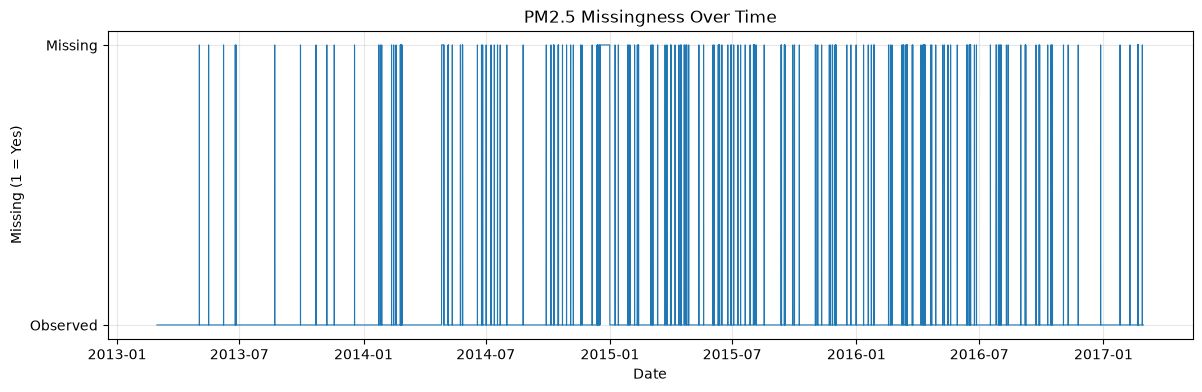

In [39]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 4))

plt.plot(
    station_df["datetime"],
    station_df["PM2.5"].isna().astype(int),
    linewidth=0.8
)

plt.title("PM2.5 Missingness Over Time")
plt.xlabel("Date")
plt.ylabel("Missing (1 = Yes)")
plt.yticks([0, 1], ["Observed", "Missing"])
plt.grid(alpha=0.3)

plt.show()

year-by-year missing-value matrix for all our environmental variables

In [41]:
missing_by_year = station_df.groupby("year")[numeric_columns].apply(lambda x: x.isna().sum())

missing_by_year

,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
year,,,,,,,,,,,
2013,11,5,101,49,864,565,0,0,0,0,0
2014,505,487,573,614,585,597,0,0,0,0,0
2015,216,100,108,118,165,255,2,2,2,2,2
2016,177,111,134,223,128,279,7,7,7,7,5
2017,16,15,19,19,34,23,11,11,11,11,7


Let's determine how much of the dataset has complete PM2.5 + weather information.

In [43]:
core_columns = [
    "PM2.5", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

complete_core = station_df[core_columns].notna().all(axis=1)

print("Complete PM2.5 + weather rows:", complete_core.sum())
print("Incomplete rows:", (~complete_core).sum())
print(
    "Complete percentage:",
    round(complete_core.mean() * 100, 2),
    "%"
)

Complete PM2.5 + weather rows: 34119
Incomplete rows: 945
Complete percentage: 97.3 %


inspect the wind-direction column

In [45]:
print("Unique wind directions:")
print(station_df["wd"].value_counts(dropna=False))

Unique wind directions:
wd
NE     5140
ENE    3950
SW     3359
E      2608
NNE    2445
WSW    2212
SSW    2098
N      2066
NW     1860
ESE    1717
NNW    1589
SE     1341
S      1304
W      1171
WNW    1101
SSE    1022
NaN      81
Name: count, dtype: int64


We aren't actually cleaning anything yet — we're just creating a safe copy so that all preprocessing from this point onward can be reproduced without altering the original data

In [47]:
station_clean = station_df.copy()

print("Raw rows:", len(station_df))
print("Clean working rows:", len(station_clean))

Raw rows: 35064
Clean working rows: 35064


create a proper time index

In [49]:
station_clean = station_clean.set_index("datetime").sort_index()

print(station_clean.index.name)
print(station_clean.index.is_monotonic_increasing)
print(station_clean.index.is_unique)

datetime
True
True


For weather measurements, time interpolation is reasonable for such short gaps because these physical variables generally change continuously rather than jumping arbitrarily between hours.
But before we actually fill them, let's see how long their missing gaps are.

In [51]:
weather_columns = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]

for column in weather_columns:
    missing = station_clean[column].isna()
    groups = (missing != missing.shift()).cumsum()
    gaps = missing[missing].groupby(groups).size()

    print(f"{column}: {len(gaps)} missing gaps | longest gap: {gaps.max()} hour(s)")

TEMP: 8 missing gaps | longest gap: 6 hour(s)
PRES: 8 missing gaps | longest gap: 6 hour(s)
DEWP: 8 missing gaps | longest gap: 6 hour(s)
RAIN: 8 missing gaps | longest gap: 6 hour(s)
WSPM: 5 missing gaps | longest gap: 5 hour(s)


create missingness flags

In [53]:
for column in weather_columns:
    station_clean[f"{column}_was_missing"] = station_clean[column].isna()

print("Missingness flags created.")

Missingness flags created.


interpolate only the weather variables

In [55]:
station_clean[weather_columns] = station_clean[weather_columns].interpolate(
    method="time"
)

print("Weather interpolation completed.")
print(station_clean[weather_columns].isna().sum())

Weather interpolation completed.
TEMP    0
PRES    0
DEWP    0
RAIN    0
WSPM    0
dtype: int64


let's inspect its missing gaps

In [57]:
wd_missing = station_clean["wd"].isna()

groups = (wd_missing != wd_missing.shift()).cumsum()

wd_gaps = (
    wd_missing[wd_missing]
    .groupby(groups)
    .size()
)

print("Number of missing wind-direction gaps:", len(wd_gaps))
print("\nGap lengths:")
print(wd_gaps.value_counts().sort_index())
print("\nLongest gap:", wd_gaps.max(), "hour(s)")

Number of missing wind-direction gaps: 63

Gap lengths:
wd
1    56
2     2
3     1
4     2
5     2
Name: count, dtype: int64

Longest gap: 5 hour(s)


We have 81 missing wind-direction values across 63 gaps, and the longest gap is only 5 hours. Since wd is categorical, we won't numerically interpolate it.
For such short gaps, we'll use forward-fill and keep a flag so we know which values were filled.

In [59]:
station_clean["wd_was_missing"] = station_clean["wd"].isna()

station_clean["wd"] = station_clean["wd"].ffill()

print("Wind direction gaps filled.")
print("Remaining missing values:", station_clean["wd"].isna().sum())

Wind direction gaps filled.
Remaining missing values: 0


check pollutant missingness

In [61]:
pollutant_columns = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]

print(station_clean[pollutant_columns].isna().sum())

PM2.5     925
PM10      718
SO2       935
NO2      1023
CO       1776
O3       1719
dtype: int64


inspect the gap lengths for all pollutants

In [63]:
for column in pollutant_columns:
    missing = station_clean[column].isna()
    groups = (missing != missing.shift()).cumsum()

    gaps = (
        missing[missing]
        .groupby(groups)
        .size()
    )

    print(f"\n{column}")
    print("  Missing gaps:", len(gaps))
    print("  Longest gap:", gaps.max(), "hour(s)")
    print("  Gap distribution:")
    print(gaps.value_counts().sort_index().to_dict())


PM2.5
  Missing gaps: 209
  Longest gap: 343 hour(s)
  Gap distribution:
{1: 115, 2: 59, 3: 12, 4: 5, 5: 4, 6: 1, 7: 1, 8: 1, 15: 2, 19: 1, 20: 2, 22: 1, 24: 1, 25: 1, 28: 1, 64: 1, 343: 1}

PM10
  Missing gaps: 162
  Longest gap: 343 hour(s)
  Gap distribution:
{1: 99, 2: 39, 3: 8, 4: 4, 5: 4, 6: 1, 7: 2, 14: 1, 15: 1, 25: 1, 64: 1, 343: 1}

SO2
  Missing gaps: 209
  Longest gap: 343 hour(s)
  Gap distribution:
{1: 129, 2: 48, 3: 10, 4: 6, 5: 2, 6: 2, 7: 3, 8: 1, 10: 1, 14: 1, 15: 1, 25: 1, 63: 1, 64: 1, 71: 1, 343: 1}

NO2
  Missing gaps: 328
  Longest gap: 343 hour(s)
  Gap distribution:
{1: 249, 2: 44, 3: 12, 4: 5, 5: 4, 6: 2, 7: 2, 8: 1, 10: 1, 14: 1, 15: 1, 18: 1, 24: 1, 25: 1, 63: 1, 64: 1, 343: 1}

CO
  Missing gaps: 378
  Longest gap: 343 hour(s)
  Gap distribution:
{1: 241, 2: 60, 3: 17, 4: 10, 5: 7, 6: 7, 7: 9, 8: 3, 10: 3, 11: 2, 12: 2, 14: 3, 15: 2, 16: 1, 17: 1, 20: 1, 25: 1, 29: 1, 61: 1, 63: 1, 64: 1, 72: 1, 111: 1, 191: 1, 343: 1}

O3
  Missing gaps: 632
  Longest gap

the exact amount of data we'll potentially recover versus deliberately leave missing.

In [65]:
for column in pollutant_columns:
    missing = station_clean[column].isna()
    groups = (missing != missing.shift()).cumsum()

    gaps = (
        missing[missing]
        .groupby(groups)
        .size()
    )

    short_gap_values = gaps[gaps <= 3].sum()
    long_gap_values = gaps[gaps > 3].sum()

    print(
        f"{column}: "
        f"{short_gap_values} short-gap values | "
        f"{long_gap_values} long-gap values"
    )

PM2.5: 269 short-gap values | 656 long-gap values
PM10: 201 short-gap values | 517 long-gap values
SO2: 255 short-gap values | 680 long-gap values
NO2: 373 short-gap values | 650 long-gap values
CO: 412 short-gap values | 1364 long-gap values
O3: 677 short-gap values | 1042 long-gap values


create missingness flags for the pollutants
Just like we did for weather, we want to permanently remember which pollutant values were originally missing.

In [68]:
for column in pollutant_columns:
    station_clean[f"{column}_was_missing"] = station_clean[column].isna()

print("Pollutant missingness flags created.")

Pollutant missingness flags created.


use time interpolation with a limit of 3 hours

In [69]:
station_clean[pollutant_columns] = station_clean[pollutant_columns].interpolate(
    method="time",
    limit=3
)

print("Short pollutant gaps interpolated.")
print(station_clean[pollutant_columns].isna().sum())

Short pollutant gaps interpolated.
PM2.5     587
PM10      469
SO2       614
NO2       581
CO       1184
O3        871
dtype: int64


One important verification
Let's make sure our interpolation didn't accidentally fill any gap longer than 3 hours.

In [70]:
for column in pollutant_columns:
    remaining = station_clean[column].isna()
    groups = (remaining != remaining.shift()).cumsum()

    gaps = (
        remaining[remaining]
        .groupby(groups)
        .size()
    )

    print(f"{column}: longest remaining gap = {gaps.max()} hours")

PM2.5: longest remaining gap = 340 hours
PM10: longest remaining gap = 340 hours
SO2: longest remaining gap = 340 hours
NO2: longest remaining gap = 340 hours
CO: longest remaining gap = 340 hours
O3: longest remaining gap = 340 hours


check the cleaned dataset's overall status

In [71]:
remaining_missing = (
    station_clean.isna()
    .sum()
    .sort_values(ascending=False)
)

print(remaining_missing[remaining_missing > 0])

CO       1184
O3        871
SO2       614
PM2.5     587
NO2       581
PM10      469
dtype: int64


create the basic calendar features

In [72]:
station_clean["hour"] = station_clean.index.hour
station_clean["day_of_week"] = station_clean.index.dayofweek
station_clean["month"] = station_clean.index.month
station_clean["day_of_year"] = station_clean.index.dayofyear

print("Time features created.")
print(
    station_clean[
        ["hour", "day_of_week", "month", "day_of_year"]
    ].head()
)

Time features created.
                     hour  day_of_week  month  day_of_year
datetime                                                  
2013-03-01 00:00:00     0            4      3           60
2013-03-01 01:00:00     1            4      3           60
2013-03-01 02:00:00     2            4      3           60
2013-03-01 03:00:00     3            4      3           60
2013-03-01 04:00:00     4            4      3           60


onvert the cyclical features into sin/cos representations.
Why? Because ordinary numbers create a false distance:
#- 23:00 → 00:00 looks like a difference of 23
#- but in reality they're only 1 hour apart.
Sin/cos fixes that and is especially useful for our forecasting models.

In [73]:
import numpy as np

print("NumPy ready:", np.__version__)

station_clean["hour_sin"] = np.sin(
    2 * np.pi * station_clean["hour"] / 24
)
station_clean["hour_cos"] = np.cos(
    2 * np.pi * station_clean["hour"] / 24
)

station_clean["day_of_week_sin"] = np.sin(
    2 * np.pi * station_clean["day_of_week"] / 7
)
station_clean["day_of_week_cos"] = np.cos(
    2 * np.pi * station_clean["day_of_week"] / 7
)

station_clean["month_sin"] = np.sin(
    2 * np.pi * station_clean["month"] / 12
)
station_clean["month_cos"] = np.cos(
    2 * np.pi * station_clean["month"] / 12
)

print("Cyclical time features created.")
print(
    station_clean[
        [
            "hour_sin", "hour_cos",
            "day_of_week_sin", "day_of_week_cos",
            "month_sin", "month_cos"
        ]
    ].head()
)

NumPy ready: 2.5.3
Cyclical time features created.
                     hour_sin  hour_cos  day_of_week_sin  day_of_week_cos  \
datetime                                                                    
2013-03-01 00:00:00  0.000000  1.000000        -0.433884        -0.900969   
2013-03-01 01:00:00  0.258819  0.965926        -0.433884        -0.900969   
2013-03-01 02:00:00  0.500000  0.866025        -0.433884        -0.900969   
2013-03-01 03:00:00  0.707107  0.707107        -0.433884        -0.900969   
2013-03-01 04:00:00  0.866025  0.500000        -0.433884        -0.900969   

                     month_sin     month_cos  
datetime                                      
2013-03-01 00:00:00        1.0  6.123234e-17  
2013-03-01 01:00:00        1.0  6.123234e-17  
2013-03-01 02:00:00        1.0  6.123234e-17  
2013-03-01 03:00:00        1.0  6.123234e-17  
2013-03-01 04:00:00        1.0  6.123234e-17  


create the mapping

In [74]:
wind_direction_angles = {
    "N": 0,
    "NNE": 22.5,
    "NE": 45,
    "ENE": 67.5,
    "E": 90,
    "ESE": 112.5,
    "SE": 135,
    "SSE": 157.5,
    "S": 180,
    "SSW": 202.5,
    "SW": 225,
    "WSW": 247.5,
    "W": 270,
    "WNW": 292.5,
    "NW": 315,
    "NNW": 337.5
}

station_clean["wind_angle"] = station_clean["wd"].map(wind_direction_angles)

print("Wind direction mapping created.")
print(station_clean[["wd", "wind_angle"]].head())

Wind direction mapping created.
                      wd  wind_angle
datetime                            
2013-03-01 00:00:00  NNW       337.5
2013-03-01 01:00:00    N         0.0
2013-03-01 02:00:00  NNW       337.5
2013-03-01 03:00:00   NW       315.0
2013-03-01 04:00:00    N         0.0


turn that angle into the two circular features our models can actually use

In [75]:
station_clean["wind_dir_sin"] = np.sin(
    np.deg2rad(station_clean["wind_angle"])
)

station_clean["wind_dir_cos"] = np.cos(
    np.deg2rad(station_clean["wind_angle"])
)

print("Circular wind features created.")
print(
    station_clean[
        ["wd", "wind_angle", "wind_dir_sin", "wind_dir_cos"]
    ].head()
)

Circular wind features created.
                      wd  wind_angle  wind_dir_sin  wind_dir_cos
datetime                                                        
2013-03-01 00:00:00  NNW       337.5     -0.382683      0.923880
2013-03-01 01:00:00    N         0.0      0.000000      1.000000
2013-03-01 02:00:00  NNW       337.5     -0.382683      0.923880
2013-03-01 03:00:00   NW       315.0     -0.707107      0.707107
2013-03-01 04:00:00    N         0.0      0.000000      1.000000


quick feature sanity check

In [76]:
feature_check = station_clean[
    [
        "hour",
        "day_of_week",
        "month",
        "hour_sin",
        "hour_cos",
        "day_of_week_sin",
        "day_of_week_cos",
        "month_sin",
        "month_cos",
        "wind_angle",
        "wind_dir_sin",
        "wind_dir_cos"
    ]
]

print("Feature shape:", feature_check.shape)
print("\nMissing values:")
print(feature_check.isna().sum())

print("\nValue ranges:")
print(feature_check.describe().loc[["min", "max"]])

Feature shape: (35064, 12)

Missing values:
hour               0
day_of_week        0
month              0
hour_sin           0
hour_cos           0
day_of_week_sin    0
day_of_week_cos    0
month_sin          0
month_cos          0
wind_angle         0
wind_dir_sin       0
wind_dir_cos       0
dtype: int64

Value ranges:
     hour  day_of_week  month  hour_sin  hour_cos  day_of_week_sin  \
min   0.0          0.0    1.0      -1.0      -1.0        -0.974928   
max  23.0          6.0   12.0       1.0       1.0         0.974928   

     day_of_week_cos  month_sin  month_cos  wind_angle  wind_dir_sin  \
min        -0.900969       -1.0       -1.0         0.0          -1.0   
max         1.000000        1.0        1.0       337.5           1.0   

     wind_dir_cos  
min          -1.0  
max           1.0  


PM2.5 distribution

In [77]:
pm25 = station_clean["PM2.5"].dropna()

print("PM2.5 observations:", len(pm25))
print("Mean:", pm25.mean())
print("Median:", pm25.median())
print("Std:", pm25.std())
print("Minimum:", pm25.min())
print("Maximum:", pm25.max())

print("\nPercentiles:")
print(pm25.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

PM2.5 observations: 34477
Mean: 82.78840433565425
Median: 58.0
Std: 82.20744807475725
Minimum: 3.0
Maximum: 898.0

Percentiles:
0.01      3.0
0.05      7.0
0.25     22.0
0.50     58.0
0.75    114.0
0.95    248.0
0.99    378.0
Name: PM2.5, dtype: float64


visualize the PM2.5 distribution

Seaborn ready: 0.13.2


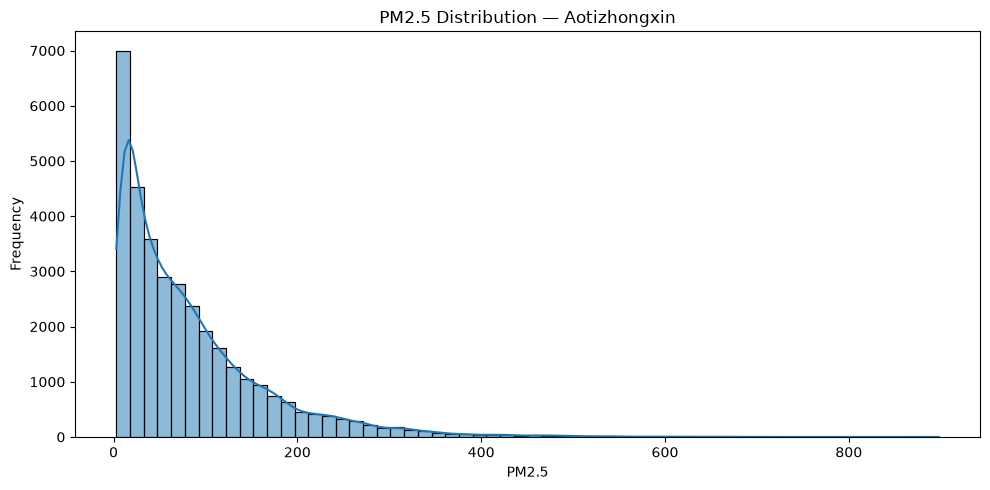

In [78]:
import seaborn as sns

print("Seaborn ready:", sns.__version__)
plt.figure(figsize=(10, 5))

sns.histplot(
    pm25,
    bins=60,
    kde=True
)

plt.title("PM2.5 Distribution — Aotizhongxin")
plt.xlabel("PM2.5")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

PM2.5 over the entire timeline

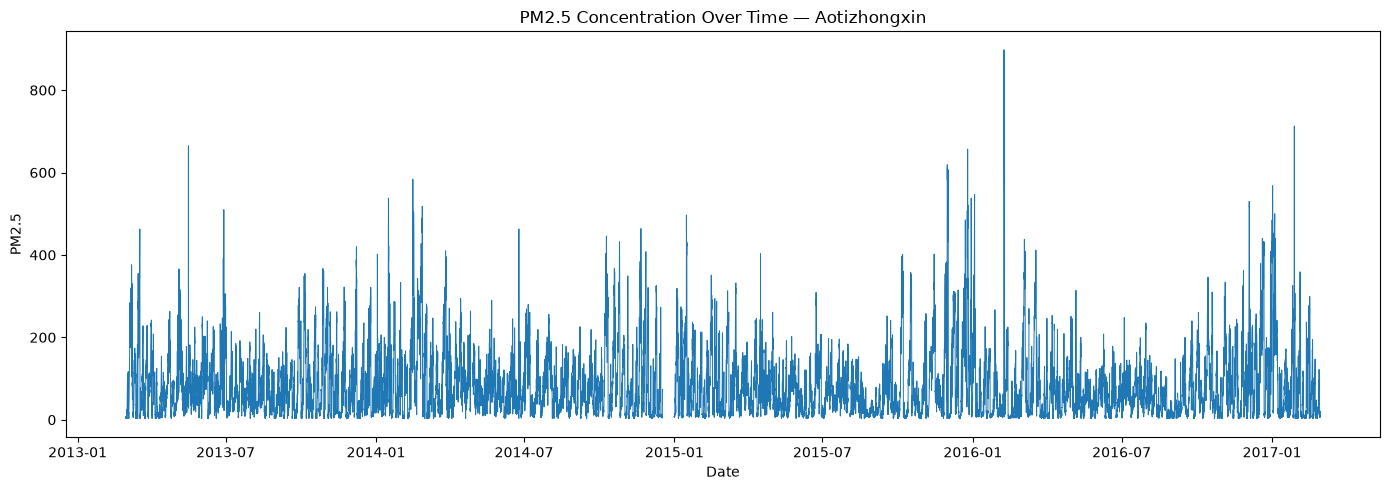

In [79]:
plt.figure(figsize=(14, 5))

plt.plot(
    station_clean.index,
    station_clean["PM2.5"],
    linewidth=0.7
)

plt.title("PM2.5 Concentration Over Time — Aotizhongxin")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

PM2.5 by hour of day

In [80]:
hourly_pm25 = (
    station_clean
    .groupby("hour")["PM2.5"]
    .mean()
)

print(hourly_pm25)

hour
0     92.257491
1     92.596167
2     91.811530
3     88.753510
4     85.174454
5     81.783659
6     79.735356
7     77.795514
8     77.580604
9     78.711320
10    79.308047
11    79.116421
12    78.831888
13    78.279922
14    77.435344
15    76.901146
16    76.032942
17    76.366062
18    77.968730
19    81.983396
20    86.230776
21    89.355641
22    91.225157
23    91.801603
Name: PM2.5, dtype: float64


hourly PM2.5 pattern

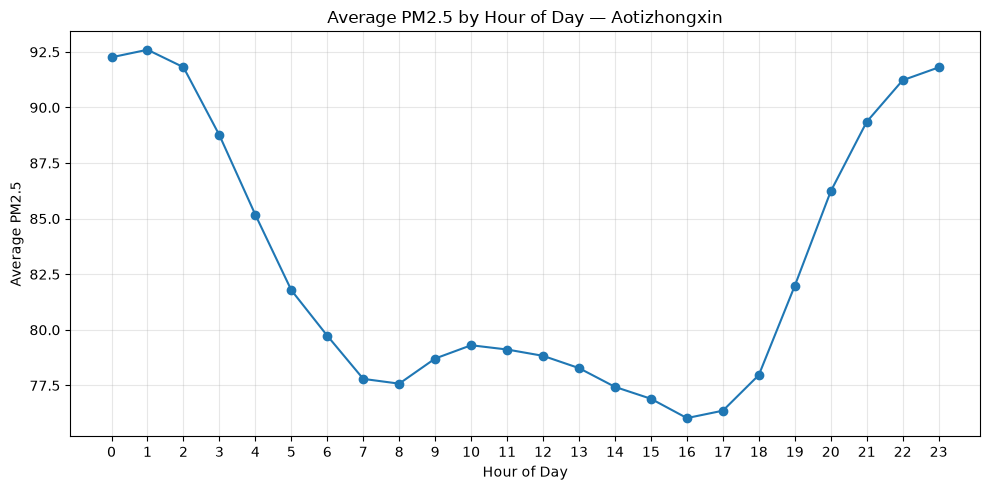

In [81]:
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_pm25.index,
    hourly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 by Hour of Day — Aotizhongxin")
plt.xlabel("Hour of Day")
plt.ylabel("Average PM2.5")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

seasonal/monthly behavior

In [82]:
monthly_pm25 = (
    station_clean
    .groupby("month")["PM2.5"]
    .mean()
)

print(monthly_pm25)

month
1      92.465859
2      86.473485
3      99.864810
4      76.406271
5      67.337399
6      71.724136
7      75.222085
8      55.796279
9      64.457493
10     96.568320
11     98.578735
12    110.841432
Name: PM2.5, dtype: float64


visualize this pattern

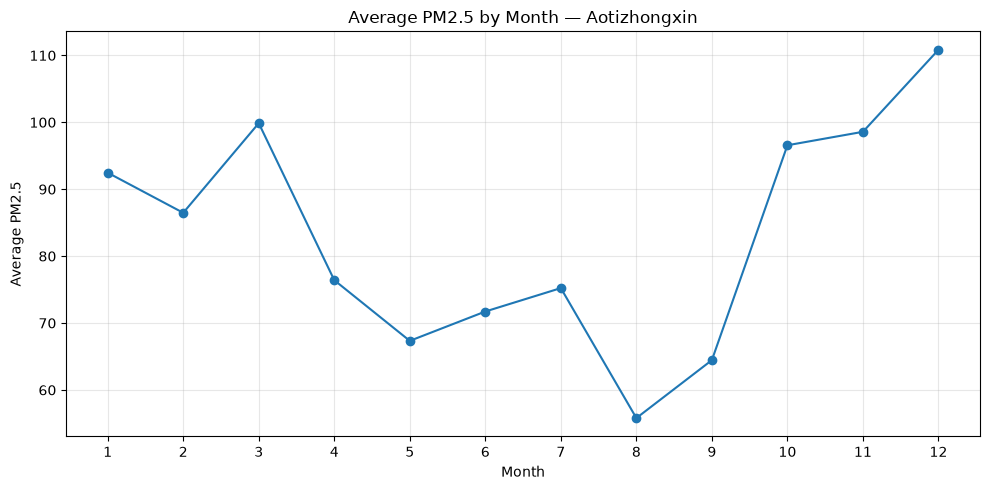

In [83]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_pm25.index,
    monthly_pm25.values,
    marker="o"
)

plt.title("Average PM2.5 by Month — Aotizhongxin")
plt.xlabel("Month")
plt.ylabel("Average PM2.5")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PM2.5 vs temperature

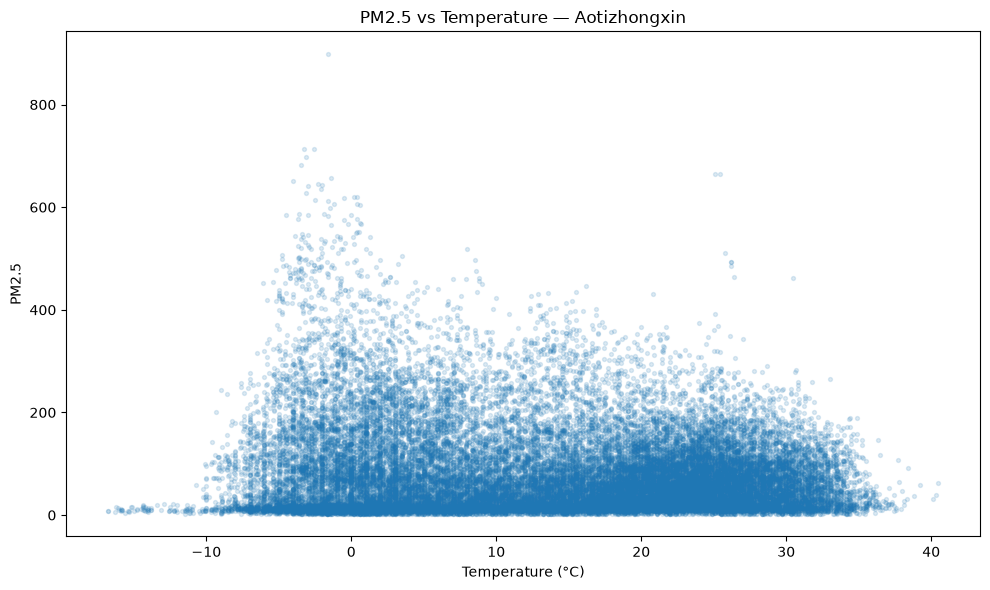

In [84]:
plt.figure(figsize=(10, 6))

plt.scatter(
    station_clean["TEMP"],
    station_clean["PM2.5"],
    alpha=0.15,
    s=8
)

plt.title("PM2.5 vs Temperature — Aotizhongxin")
plt.xlabel("Temperature (°C)")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

PM2.5 vs wind speed

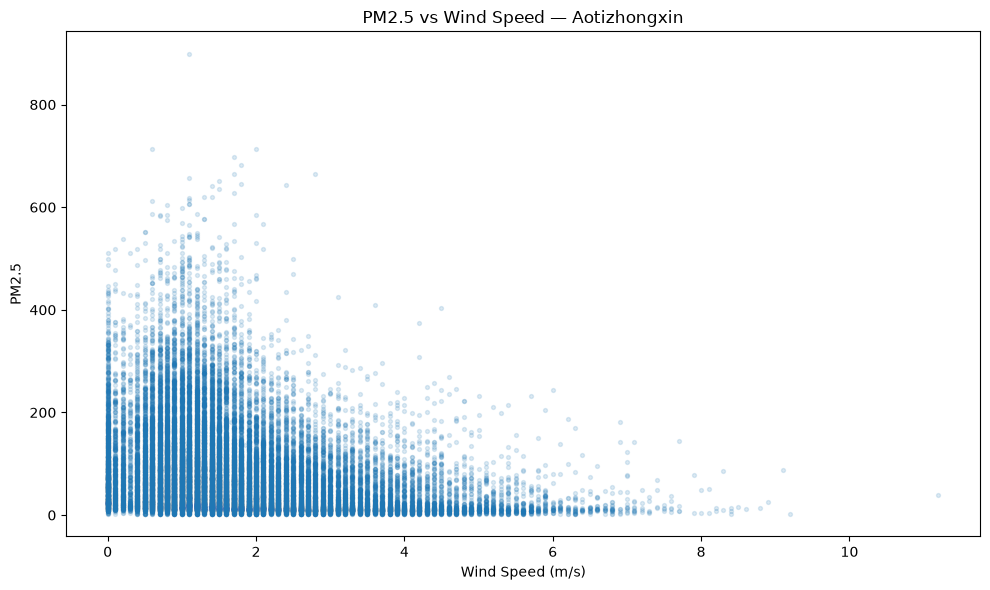

In [85]:
plt.figure(figsize=(10, 6))

plt.scatter(
    station_clean["WSPM"],
    station_clean["PM2.5"],
    alpha=0.15,
    s=8
)

plt.title("PM2.5 vs Wind Speed — Aotizhongxin")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("PM2.5")
plt.tight_layout()
plt.show()

quantify the relationships

In [86]:
correlation_columns = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM"
]

correlation_matrix = station_clean[correlation_columns].corr()

print(
    correlation_matrix["PM2.5"]
    .sort_values(ascending=False)
)

PM2.5    1.000000
PM10     0.876107
CO       0.787638
NO2      0.684406
SO2      0.482543
DEWP     0.120939
PRES    -0.005599
RAIN    -0.013965
TEMP    -0.128536
O3      -0.160537
WSPM    -0.278521
Name: PM2.5, dtype: float64


One more useful EDA step: correlation heatmap

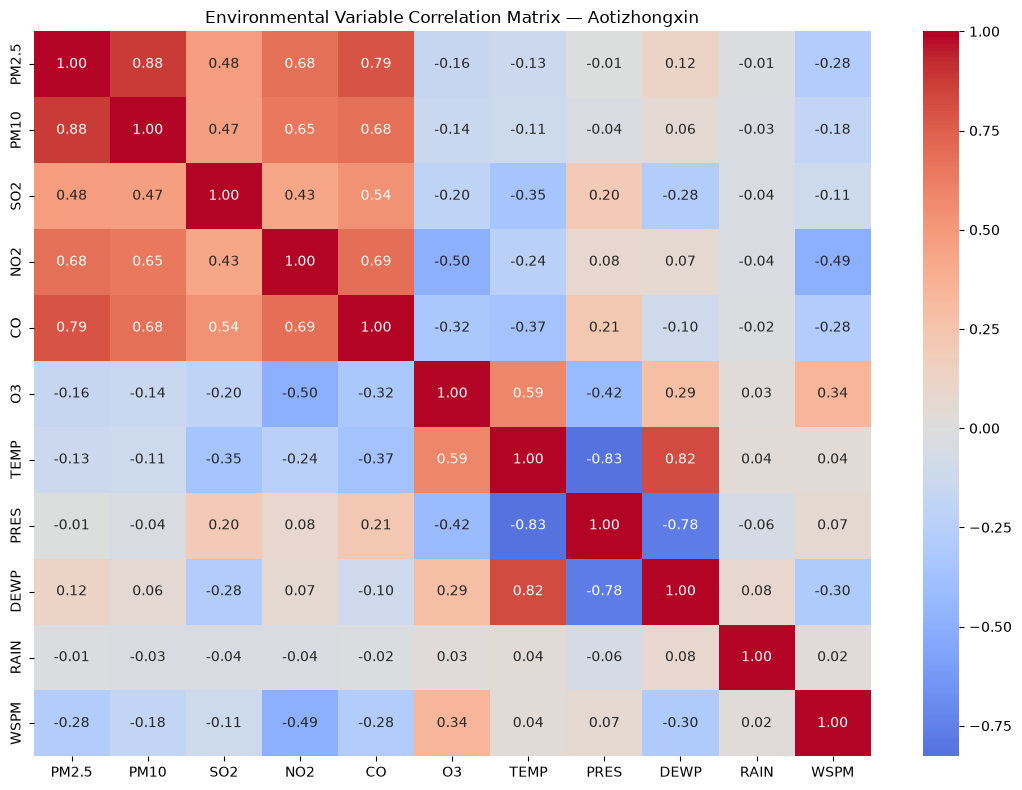

In [87]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Environmental Variable Correlation Matrix — Aotizhongxin")
plt.tight_layout()
plt.show()

identify PM2.5 pollution extremes

In [88]:
pm25_extremes = (
    station_clean[["PM2.5"]]
    .dropna()
    .sort_values("PM2.5", ascending=False)
    .head(20)
)

print(pm25_extremes)

                     PM2.5
datetime                  
2016-02-08 02:00:00  898.0
2017-01-28 05:00:00  713.0
2016-02-08 03:00:00  713.0
2017-01-28 06:00:00  697.0
2017-01-28 04:00:00  682.0
2013-05-16 12:00:00  665.0
2013-05-16 11:00:00  665.0
2015-12-25 15:00:00  657.0
2017-01-28 03:00:00  651.0
2015-12-25 13:00:00  646.0
2015-12-25 14:00:00  644.0
2017-01-28 02:00:00  641.0
2015-12-25 16:00:00  635.0
2015-12-25 12:00:00  627.0
2015-11-30 16:00:00  619.0
2015-11-30 15:00:00  619.0
2015-11-30 17:00:00  618.0
2016-02-08 04:00:00  615.0
2015-11-30 21:00:00  612.0
2015-12-01 15:00:00  607.0


Analyze rolling PM2.5 trends

In [89]:
print("Dataset available:", "station_clean" in globals())

print("PM2.5 column available:",
      "PM2.5" in station_clean.columns
      if "station_clean" in globals()
      else "Dataset not loaded")

Dataset available: True
PM2.5 column available: True


Calculate the rolling average

In [90]:
station_clean["PM2.5_24h_avg"] = (
    station_clean["PM2.5"]
    .rolling(window=24, min_periods=18)
    .mean()
)

print("24-hour rolling average created!")
print(
    station_clean[
        ["PM2.5", "PM2.5_24h_avg"]
    ].tail(10)
)

24-hour rolling average created!
                     PM2.5  PM2.5_24h_avg
datetime                                 
2017-02-28 14:00:00    5.0      31.250000
2017-02-28 15:00:00    6.0      27.541667
2017-02-28 16:00:00   12.0      24.916667
2017-02-28 17:00:00   12.0      23.000000
2017-02-28 18:00:00   13.0      21.583333
2017-02-28 19:00:00   12.0      19.958333
2017-02-28 20:00:00   13.0      18.375000
2017-02-28 21:00:00   16.0      16.833333
2017-02-28 22:00:00   21.0      15.291667
2017-02-28 23:00:00   19.0      13.166667


Visualize the pollution episodes

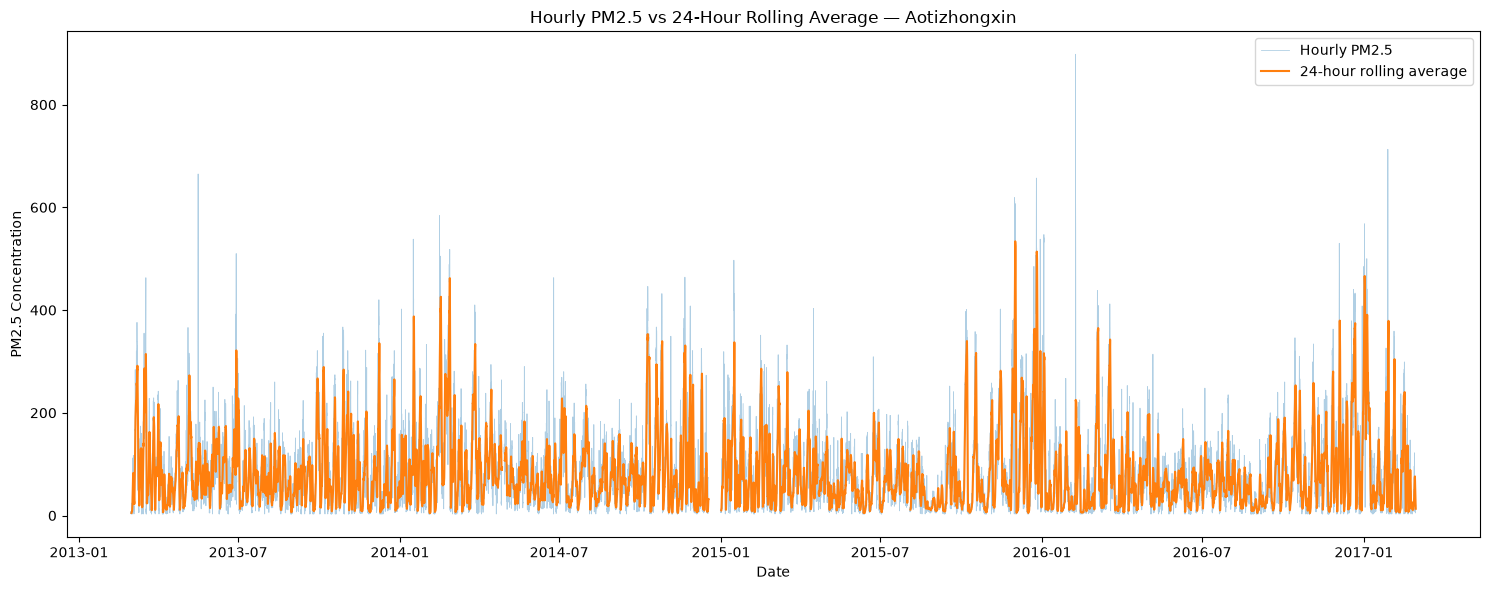

In [91]:
plt.figure(figsize=(15, 6))

plt.plot(
    station_clean.index,
    station_clean["PM2.5"],
    label="Hourly PM2.5",
    alpha=0.35,
    linewidth=0.6
)

plt.plot(
    station_clean.index,
    station_clean["PM2.5_24h_avg"],
    label="24-hour rolling average",
    linewidth=1.5
)

plt.title("Hourly PM2.5 vs 24-Hour Rolling Average — Aotizhongxin")
plt.xlabel("Date")
plt.ylabel("PM2.5 Concentration")
plt.legend()
plt.tight_layout()
plt.show()

Identify sustained high-pollution periods

In [92]:
high_pollution = station_clean[
    station_clean["PM2.5_24h_avg"] > 150
]

print("Hours with 24-hour average above 150:",
      len(high_pollution))

print("\nFirst 10 occurrences:")
print(high_pollution[["PM2.5", "PM2.5_24h_avg"]].head(10))

Hours with 24-hour average above 150: 4600

First 10 occurrences:
                     PM2.5  PM2.5_24h_avg
datetime                                 
2013-03-06 00:00:00  284.0     157.750000
2013-03-06 01:00:00  272.0     165.291667
2013-03-06 02:00:00  242.0     171.208333
2013-03-06 03:00:00  212.0     175.750000
2013-03-06 04:00:00  192.0     178.958333
2013-03-06 05:00:00  188.0     181.916667
2013-03-06 06:00:00  186.0     185.333333
2013-03-06 07:00:00  188.0     188.750000
2013-03-06 08:00:00  194.0     192.208333
2013-03-06 09:00:00  184.0     195.125000


Count distinct pollution episodes

In [93]:
high_threshold = station_clean["PM2.5_24h_avg"] > 150

episode_starts = high_threshold & ~high_threshold.shift(
    fill_value=False
)

print("Number of distinct high-pollution episodes:",
      int(episode_starts.sum()))

print("\nEpisode start times:")
print(station_clean.index[episode_starts][:10])

Number of distinct high-pollution episodes: 123

Episode start times:
DatetimeIndex(['2013-03-06 00:00:00', '2013-03-15 15:00:00',
               '2013-03-22 00:00:00', '2013-03-26 13:00:00',
               '2013-03-31 19:00:00', '2013-04-22 15:00:00',
               '2013-05-05 15:00:00', '2013-06-02 23:00:00',
               '2013-06-08 15:00:00', '2013-06-16 08:00:00'],
              dtype='datetime64[us]', name='datetime', freq=None)


Measure episode duration and severity

In [94]:
high_threshold = station_clean["PM2.5_24h_avg"] > 150

episode_id = (
    high_threshold.ne(high_threshold.shift())
    .cumsum()
)

episode_data = station_clean.loc[high_threshold].copy()
episode_data["episode_id"] = episode_id[high_threshold]

episode_summary = (
    episode_data.groupby("episode_id")
    .agg(
        start_time=("PM2.5_24h_avg", lambda x: x.index.min()),
        end_time=("PM2.5_24h_avg", lambda x: x.index.max()),
        duration_hours=("PM2.5_24h_avg", "size"),
        peak_24h_average=("PM2.5_24h_avg", "max")
    )
    .sort_values("peak_24h_average", ascending=False)
)

print("Number of episodes:", len(episode_summary))
print("\nTop 10 most severe episodes:")
print(episode_summary.head(10))

Number of episodes: 123

Top 10 most severe episodes:
                    start_time            end_time  duration_hours  \
episode_id                                                           
168        2015-11-27 18:00:00 2015-12-02 15:00:00             118   
180        2015-12-25 04:00:00 2015-12-27 06:00:00              51   
236        2016-12-30 14:00:00 2017-01-03 02:00:00              85   
72         2014-02-20 18:00:00 2014-02-27 10:00:00             161   
70         2014-02-13 14:00:00 2014-02-17 11:00:00              94   
238        2017-01-03 04:00:00 2017-01-07 23:00:00             116   
66         2014-01-15 23:00:00 2014-01-17 18:00:00              44   
226        2016-12-03 18:00:00 2016-12-05 09:00:00              40   
242        2017-01-28 04:00:00 2017-01-29 12:00:00              33   
232        2016-12-17 13:00:00 2016-12-22 18:00:00             126   

            peak_24h_average  
episode_id                    
168               533.895833  
180         

Visualize the top 10 episodes

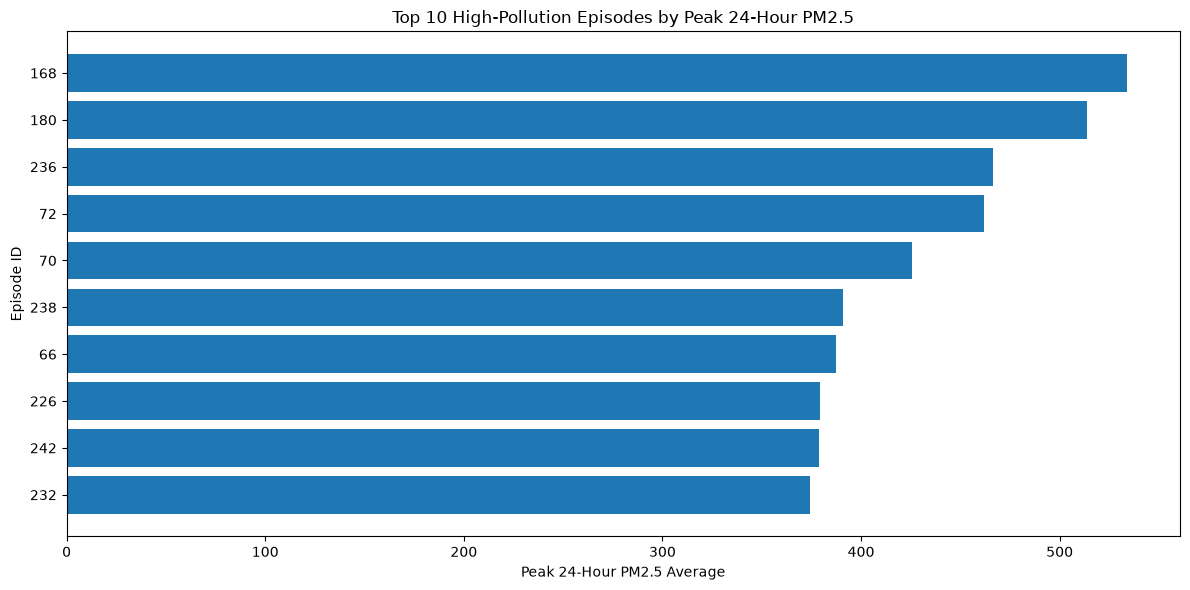

In [95]:
top_episodes = episode_summary.head(10).sort_values(
    "peak_24h_average"
)

plt.figure(figsize=(12, 6))

plt.barh(
    top_episodes.index.astype(str),
    top_episodes["peak_24h_average"]
)

plt.title("Top 10 High-Pollution Episodes by Peak 24-Hour PM2.5")
plt.xlabel("Peak 24-Hour PM2.5 Average")
plt.ylabel("Episode ID")
plt.tight_layout()
plt.show()

Compare episode duration and intensity
# X-axis: Episode duration in hours.
# Y-axis: Peak 24-hour rolling-average PM2.5.
# Each dot: One of the 123 identified episodes.

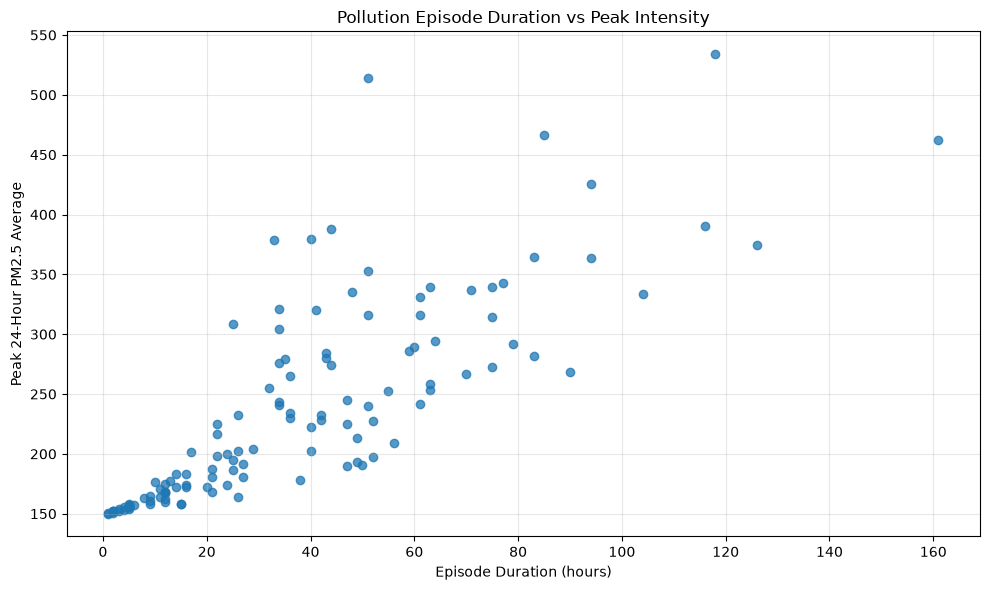

In [96]:
plt.figure(figsize=(10, 6))

plt.scatter(
    episode_summary["duration_hours"],
    episode_summary["peak_24h_average"],
    alpha=0.75
)

plt.title("Pollution Episode Duration vs Peak Intensity")
plt.xlabel("Episode Duration (hours)")
plt.ylabel("Peak 24-Hour PM2.5 Average")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Measure the relationship

In [97]:
duration_intensity_corr = episode_summary[
    ["duration_hours", "peak_24h_average"]
].corr(method="spearman").iloc[0, 1]

print(f"Spearman correlation: {duration_intensity_corr:.3f}")

Spearman correlation: 0.889


Define our forecasting target

In [98]:
# Define the one-hour-ahead forecasting target
forecast_df = station_clean.copy()

forecast_df["PM2.5_next_hour"] = (
    forecast_df["PM2.5"].shift(-1)
)

print("Forecasting dataset shape:", forecast_df.shape)
print("\nCurrent PM2.5:")
print(forecast_df["PM2.5"].head())

print("\nNext-hour PM2.5 target:")
print(forecast_df["PM2.5_next_hour"].head())

Forecasting dataset shape: (35064, 43)

Current PM2.5:
datetime
2013-03-01 00:00:00    4.0
2013-03-01 01:00:00    8.0
2013-03-01 02:00:00    7.0
2013-03-01 03:00:00    6.0
2013-03-01 04:00:00    3.0
Name: PM2.5, dtype: float64

Next-hour PM2.5 target:
datetime
2013-03-01 00:00:00    8.0
2013-03-01 01:00:00    7.0
2013-03-01 02:00:00    6.0
2013-03-01 03:00:00    3.0
2013-03-01 04:00:00    5.0
Name: PM2.5_next_hour, dtype: float64


Check target availability

In [99]:
# Check availability of the forecasting target
target_col = "PM2.5_next_hour"

print("Total rows:", len(forecast_df))
print("Available targets:", forecast_df[target_col].notna().sum())
print("Missing targets:", forecast_df[target_col].isna().sum())

print(
    "Target availability (%):",
    round(forecast_df[target_col].notna().mean() * 100, 2)
)

print("\nTarget summary:")
print(forecast_df[target_col].describe())

Total rows: 35064
Available targets: 34476
Missing targets: 588
Target availability (%): 98.32

Target summary:
count    34476.000000
mean        82.790690
std         82.207545
min          3.000000
25%         22.000000
50%         58.000000
75%        114.000000
max        898.000000
Name: PM2.5_next_hour, dtype: float64


Create chronological training, validation, and test periods

In [100]:
# Define chronological split boundaries
n_rows = len(forecast_df)

train_end = int(n_rows * 0.70)
val_end = int(n_rows * 0.85)

train_df = forecast_df.iloc[:train_end].copy()
val_df = forecast_df.iloc[train_end:val_end].copy()
test_df = forecast_df.iloc[val_end:].copy()

print("Training period:")
print(train_df.index.min(), "to", train_df.index.max())
print("Rows:", len(train_df))

print("\nValidation period:")
print(val_df.index.min(), "to", val_df.index.max())
print("Rows:", len(val_df))

print("\nTest period:")
print(test_df.index.min(), "to", test_df.index.max())
print("Rows:", len(test_df))

Training period:
2013-03-01 00:00:00 to 2015-12-18 15:00:00
Rows: 24544

Validation period:
2015-12-18 16:00:00 to 2016-07-24 19:00:00
Rows: 5260

Test period:
2016-07-24 20:00:00 to 2017-02-28 23:00:00
Rows: 5260


Check target availability in each split

In [101]:
# Check valid forecasting targets in each period
for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    valid = split["PM2.5_next_hour"].notna().sum()
    missing = split["PM2.5_next_hour"].isna().sum()

    print(
        f"{name}: {valid:,} valid targets, "
        f"{missing:,} missing targets "
        f"({valid / len(split) * 100:.2f}% available)"
    )

Training: 24,034 valid targets, 510 missing targets (97.92% available)
Validation: 5,217 valid targets, 43 missing targets (99.18% available)
Test: 5,225 valid targets, 35 missing targets (99.33% available)


Select the first forecasting features

In [102]:
# Define candidate predictors for the first forecasting model
candidate_features = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
    "hour", "day_of_week", "month",
    "hour_sin", "hour_cos",
    "day_of_week_sin", "day_of_week_cos",
    "month_sin", "month_cos"
]

available_features = [
    col for col in candidate_features
    if col in forecast_df.columns
]

missing_features = [
    col for col in candidate_features
    if col not in forecast_df.columns
]

print("Available features:", len(available_features))
print(available_features)

print("\nFeatures not found:", missing_features)

Available features: 20
['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'hour', 'day_of_week', 'month', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos']

Features not found: []


Prepare the feature matrix

In [103]:
# Prepare feature and target data for each chronological split
target_col = "PM2.5_next_hour"

X_train = train_df[available_features].copy()
y_train = train_df[target_col].copy()

X_val = val_df[available_features].copy()
y_val = val_df[target_col].copy()

X_test = test_df[available_features].copy()
y_test = test_df[target_col].copy()

# Inspect missing values in predictors and targets
for name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"\n{name}")
    print("Rows:", len(X))
    print("Missing target values:", y.isna().sum())
    print("Rows with at least one missing feature:", X.isna().any(axis=1).sum())


Training
Rows: 24544
Missing target values: 510
Rows with at least one missing feature: 1598

Validation
Rows: 5260
Missing target values: 43
Rows with at least one missing feature: 72

Test
Rows: 5260
Missing target values: 35
Rows with at least one missing feature: 47


Impute missing predictor values safely

In [104]:
from sklearn.impute import SimpleImputer

# Fit imputation rules using training data only
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_val_imputed = pd.DataFrame(
    imputer.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing predictors after imputation:")
print("Training:", X_train_imputed.isna().sum().sum())
print("Validation:", X_val_imputed.isna().sum().sum())
print("Test:", X_test_imputed.isna().sum().sum())

Missing predictors after imputation:
Training: 0
Validation: 0
Test: 0


Train a baseline model

In [105]:
from sklearn.ensemble import RandomForestRegressor

# Keep only rows with known training targets
train_valid = y_train.notna()

X_train_model = X_train_imputed.loc[train_valid]
y_train_model = y_train.loc[train_valid]

print("Rows used for training:", len(X_train_model))

# Train the baseline model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_model, y_train_model)

print("\nRandom Forest training completed successfully.")

Rows used for training: 24034

Random Forest training completed successfully.


Evaluate on validation data

In [106]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Keep only validation rows with known targets
val_valid = y_val.notna()

X_val_model = X_val_imputed.loc[val_valid]
y_val_model = y_val.loc[val_valid]

# Generate predictions
val_predictions = rf_model.predict(X_val_model)

# Calculate evaluation metrics
val_mae = mean_absolute_error(y_val_model, val_predictions)
val_rmse = np.sqrt(mean_squared_error(y_val_model, val_predictions))
val_r2 = r2_score(y_val_model, val_predictions)

print("Random Forest — Validation Results")
print("---------------------------------")
print(f"Valid validation samples: {len(y_val_model):,}")
print(f"MAE:  {val_mae:.3f} µg/m³")
print(f"RMSE: {val_rmse:.3f} µg/m³")
print(f"R²:   {val_r2:.4f}")

Random Forest — Validation Results
---------------------------------
Valid validation samples: 5,217
MAE:  10.449 µg/m³
RMSE: 20.053 µg/m³
R²:   0.9436


Compare against a persistence baseline

In [107]:
# Persistence baseline: next hour's PM2.5 equals current-hour PM2.5
persistence_predictions = val_df.loc[
    val_valid, "PM2.5"
]

# Evaluate only rows with both a known target and current PM2.5
persistence_valid = persistence_predictions.notna()

y_persistence = y_val_model.loc[persistence_valid]
persistence_predictions = persistence_predictions.loc[persistence_valid]

persistence_mae = mean_absolute_error(
    y_persistence, persistence_predictions
)
persistence_rmse = np.sqrt(mean_squared_error(
    y_persistence, persistence_predictions
))
persistence_r2 = r2_score(
    y_persistence, persistence_predictions
)

print("Persistence Baseline — Validation Results")
print("----------------------------------------")
print("Valid samples:", len(y_persistence))
print(f"MAE:  {persistence_mae:.3f} µg/m³")
print(f"RMSE: {persistence_rmse:.3f} µg/m³")
print(f"R²:   {persistence_r2:.4f}")

Persistence Baseline — Validation Results
----------------------------------------
Valid samples: 5214
MAE:  10.132 µg/m³
RMSE: 20.469 µg/m³
R²:   0.9412


Make the comparison fair

In [108]:
# Compare both models on identical validation timestamps
common_idx = y_val_model.index.intersection(
    persistence_predictions.index
)

y_common = y_val_model.loc[common_idx]
rf_common = pd.Series(
    val_predictions,
    index=y_val_model.index
).loc[common_idx]

persistence_common = persistence_predictions.loc[common_idx]

print("Common validation samples:", len(common_idx))
print("\nRandom Forest")
print(f"MAE:  {mean_absolute_error(y_common, rf_common):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_common, rf_common)):.3f}")
print(f"R²:   {r2_score(y_common, rf_common):.4f}")

print("\nPersistence")
print(f"MAE:  {mean_absolute_error(y_common, persistence_common):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_common, persistence_common)):.3f}")
print(f"R²:   {r2_score(y_common, persistence_common):.4f}")

Common validation samples: 5214

Random Forest
MAE:  10.439
RMSE: 20.045
R²:   0.9436

Persistence
MAE:  10.132
RMSE: 20.469
R²:   0.9412


Interpret the baseline comparison
#Validation · 5,214 identical timestamps
*/Random Forest MAE
10.439
µg/m³

Persistence MAE
10.132
µg/m³

Random Forest RMSE
20.045

Persistence RMSE
20.469

Random Forest reduces RMSE by approximately 2.07%, but its MAE is approximately 3.03% higher than persistence.*/

Examine feature importance

Top 10 features:
PM2.5    0.9470
PM10     0.0076
WSPM     0.0066
DEWP     0.0050
NO2      0.0049
CO       0.0034
PRES     0.0033
SO2      0.0033
O3       0.0033
TEMP     0.0032
dtype: float64


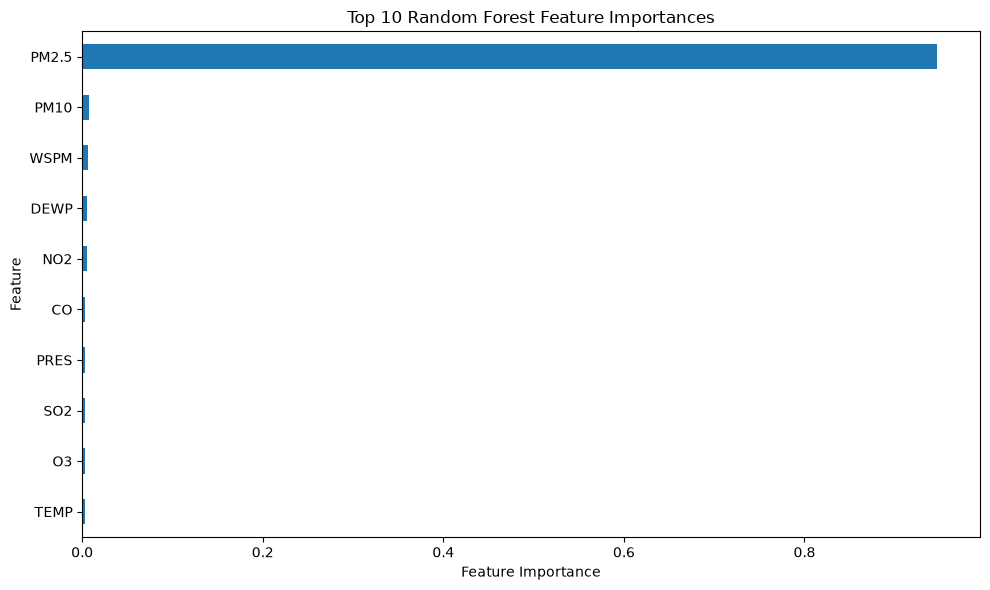

In [109]:
# Extract Random Forest feature importances
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train_model.columns
).sort_values(ascending=False)

print("Top 10 features:")
print(feature_importance.head(10).round(4))

# Visualize the top 10 features
plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [ ]:
print(feature_importance.head(10).to_string())
print(
    "\nTotal importance:",
    round(feature_importance.sum(), 4)
)

Calculate permutation importance

In [110]:

from sklearn.inspection import permutation_importance

# Use a smaller validation sample to reduce memory usage
sample_size = min(1500, len(X_val_model))

X_val_sample = X_val_model.sample(
    n=sample_size,
    random_state=42
)

y_val_sample = y_val_model.loc[X_val_sample.index]

# Calculate permutation importance without parallel workers
perm_result = permutation_importance(
    rf_model,
    X_val_sample,
    y_val_sample,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

permutation_importance_df = pd.DataFrame({
    "feature": X_val_sample.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

print("Top 10 features by permutation importance:")
print(
    permutation_importance_df.head(10)
    .round(4)
    .to_string(index=False)
)


Top 10 features by permutation importance:
    feature  importance_mean  importance_std
      PM2.5          56.2232          0.7585
       PM10           3.9189          0.2238
         O3           2.2931          0.4208
        NO2           2.1746          0.0499
       WSPM           1.5410          0.3175
      month           0.9427          0.1720
       DEWP           0.8589          0.0986
         CO           0.3804          0.0180
        SO2           0.2733          0.0512
day_of_week           0.0887          0.0306


Actual vs predicted PM2.5

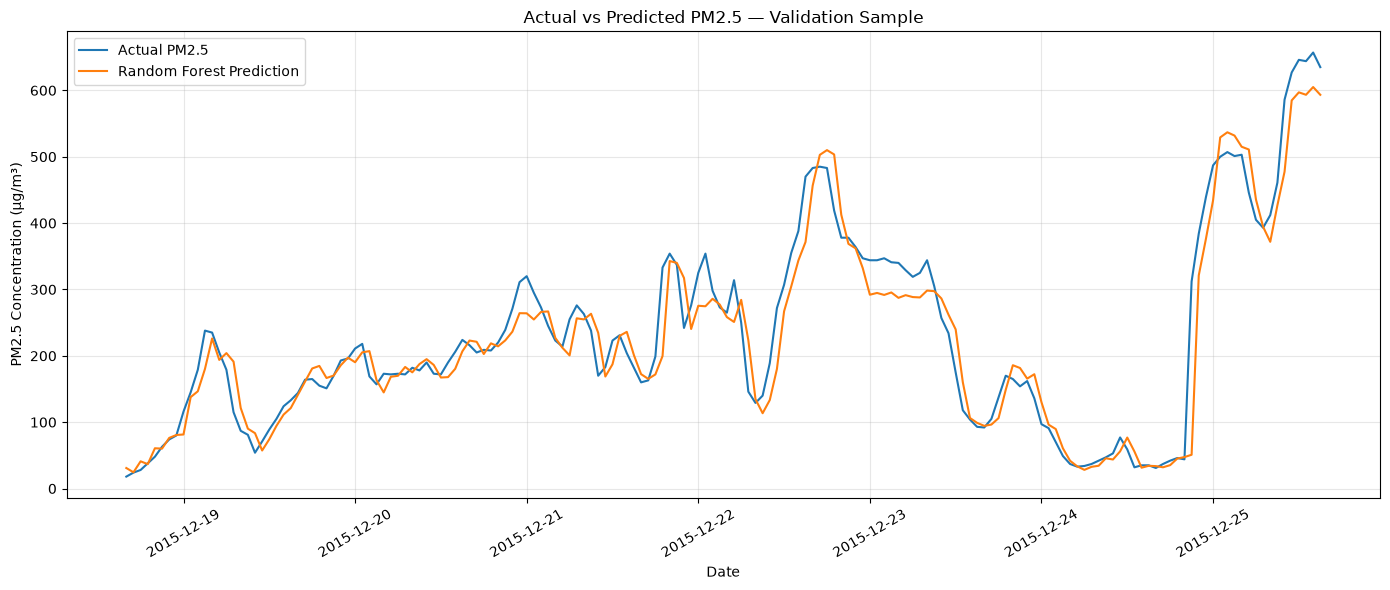

In [111]:
# Compare actual and predicted PM2.5 over one week

comparison_df = pd.DataFrame({
    "Actual PM2.5": y_val_model,
    "Predicted PM2.5": val_predictions
}, index=y_val_model.index)

week_df = comparison_df.head(168)

plt.figure(figsize=(14, 6))

plt.plot(
    week_df.index,
    week_df["Actual PM2.5"],
    label="Actual PM2.5",
    linewidth=1.5
)

plt.plot(
    week_df.index,
    week_df["Predicted PM2.5"],
    label="Random Forest Prediction",
    linewidth=1.5
)

plt.title("Actual vs Predicted PM2.5 — Validation Sample")
plt.xlabel("Date")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.legend()
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
print("Test features:", X_test_imputed.shape)
print("Test target:", y_test.shape)
print("Trained model:", type(rf_model).__name__)

Generate test predictions and calculate metrics

In [112]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Keep only rows with an observed next-hour PM2.5 target
test_valid = y_test.notna()

X_test_model = X_test_imputed.loc[test_valid]
y_test_model = y_test.loc[test_valid]

# Generate predictions
test_predictions = rf_model.predict(X_test_model)

# Evaluate model performance
test_mae = mean_absolute_error(y_test_model, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test_model, test_predictions))
test_r2 = r2_score(y_test_model, test_predictions)

print("Random Forest — Test Set Results")
print("-" * 40)
print(f"Test samples: {len(y_test_model)}")
print(f"MAE:  {test_mae:.3f} µg/m³")
print(f"RMSE: {test_rmse:.3f} µg/m³")
print(f"R²:   {test_r2:.4f}")

Random Forest — Test Set Results
----------------------------------------
Test samples: 5225
MAE:  10.953 µg/m³
RMSE: 20.310 µg/m³
R²:   0.9524


Evaluate the persistence baseline on the same test timestamps

In [113]:
# Current-hour PM2.5 used as the next-hour prediction
current_pm25 = forecast_df.loc[y_test_model.index, "PM2.5"]

# Use only timestamps where both current and next-hour PM2.5 are observed
baseline_valid = current_pm25.notna()

y_test_common = y_test_model.loc[baseline_valid]
rf_test_common = pd.Series(
    test_predictions,
    index=y_test_model.index
).loc[baseline_valid]

baseline_predictions = current_pm25.loc[baseline_valid]

# Calculate metrics on identical timestamps
baseline_mae = mean_absolute_error(
    y_test_common, baseline_predictions
)
baseline_rmse = np.sqrt(mean_squared_error(
    y_test_common, baseline_predictions
))
baseline_r2 = r2_score(
    y_test_common, baseline_predictions
)

rf_common_mae = mean_absolute_error(
    y_test_common, rf_test_common
)
rf_common_rmse = np.sqrt(mean_squared_error(
    y_test_common, rf_test_common
))
rf_common_r2 = r2_score(
    y_test_common, rf_test_common
)

comparison = pd.DataFrame({
    "Model": ["Random Forest", "Persistence Baseline"],
    "MAE": [rf_common_mae, baseline_mae],
    "RMSE": [rf_common_rmse, baseline_rmse],
    "R²": [rf_common_r2, baseline_r2]
})

print(f"Common test timestamps: {len(y_test_common)}")
print(comparison.round(4).to_string(index=False))

Common test timestamps: 5223
               Model     MAE    RMSE     R²
       Random Forest 10.9444 20.3019 0.9525
Persistence Baseline 10.9502 20.7748 0.9503


examine test-set predictions visually

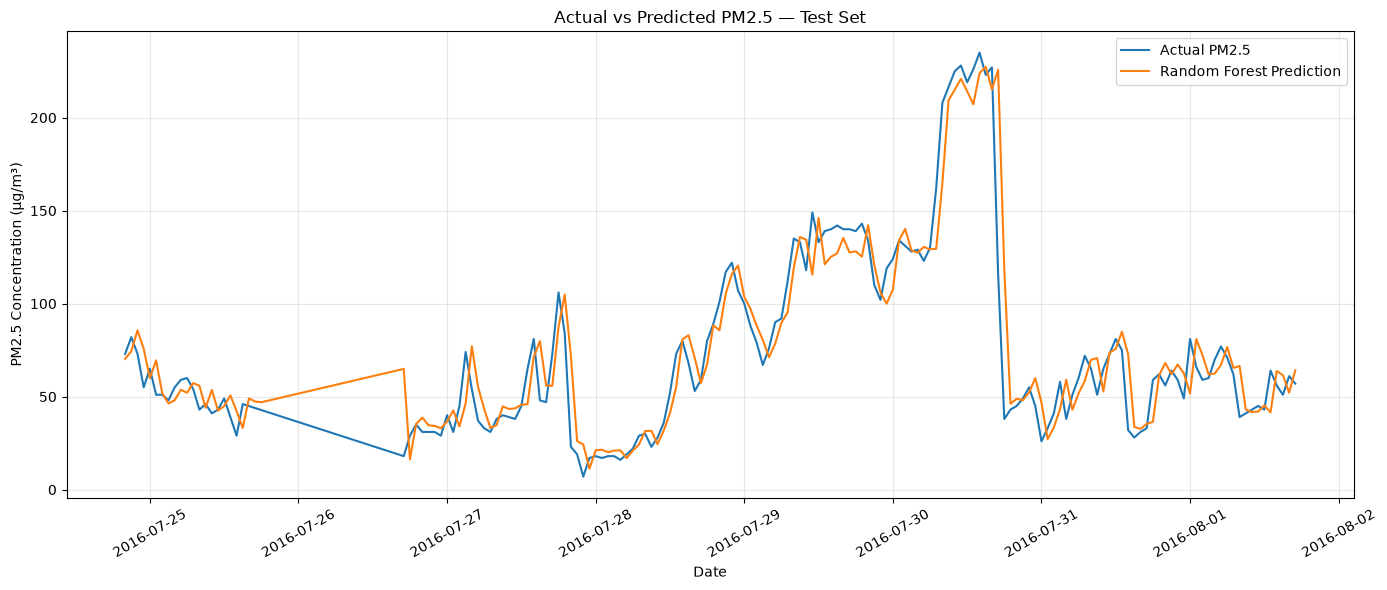

In [114]:
comparison_df = pd.DataFrame({
    "Actual PM2.5": y_test_model,
    "Predicted PM2.5": test_predictions
}, index=y_test_model.index)

# Display the first 168 valid test observations (approximately one week)
week_df = comparison_df.head(168)

plt.figure(figsize=(14, 6))
plt.plot(
    week_df.index,
    week_df["Actual PM2.5"],
    label="Actual PM2.5",
    linewidth=1.5
)
plt.plot(
    week_df.index,
    week_df["Predicted PM2.5"],
    label="Random Forest Prediction",
    linewidth=1.5
)

plt.title("Actual vs Predicted PM2.5 — Test Set")
plt.xlabel("Date")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.legend()
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

check whether the model captures extreme pollution

In [115]:
# Evaluate errors by observed PM2.5 concentration
test_results = pd.DataFrame({
    "Actual": y_test_model,
    "Predicted": test_predictions
}, index=y_test_model.index)

test_results["Absolute Error"] = (
    test_results["Actual"] - test_results["Predicted"]
).abs()

test_results["Pollution Level"] = pd.cut(
    test_results["Actual"],
    bins=[-np.inf, 35, 75, 150, np.inf],
    labels=["Low (≤35)", "Moderate (35–75)",
            "High (75–150)", "Very High (>150)"]
)

level_summary = test_results.groupby(
    "Pollution Level", observed=True
).agg(
    Samples=("Actual", "size"),
    Mean_Actual=("Actual", "mean"),
    MAE=("Absolute Error", "mean")
)

print(level_summary.round(2).to_string())

                  Samples  Mean_Actual    MAE
Pollution Level                              
Low (≤35)            2094        15.84   5.47
Moderate (35–75)     1024        54.70   9.36
High (75–150)        1087       108.12  12.85
Very High (>150)     1020       241.68  21.78


In [116]:
test_results["Signed Error"] = (
    test_results["Predicted"] - test_results["Actual"]
)

bias_summary = test_results.groupby(
    "Pollution Level", observed=True
).agg(
    Samples=("Signed Error", "size"),
    Mean_Signed_Error=("Signed Error", "mean"),
    MAE=("Absolute Error", "mean")
)

print(bias_summary.round(2).to_string())

                  Samples  Mean_Signed_Error    MAE
Pollution Level                                    
Low (≤35)            2094               2.80   5.47
Moderate (35–75)     1024               1.69   9.36
High (75–150)        1087              -1.55  12.85
Very High (>150)     1020              -7.55  21.78


In [117]:
# Identify observations with the largest absolute prediction errors
largest_errors = test_results.nlargest(
    10, "Absolute Error"
)[["Actual", "Predicted", "Absolute Error", "Signed Error"]]

print(largest_errors.round(2).to_string())

                     Actual  Predicted  Absolute Error  Signed Error
datetime                                                            
2017-01-28 00:00:00   576.0     293.54          282.46       -282.46
2017-02-15 13:00:00     3.0     230.45          227.45        227.45
2016-12-22 02:00:00   149.0     368.15          219.15        219.15
2017-02-04 19:00:00    82.0     270.68          188.68        188.68
2017-01-02 03:00:00   211.0     399.24          188.24        188.24
2017-01-28 04:00:00   713.0     534.63          178.37       -178.37
2017-01-04 11:00:00   167.0     329.21          162.21        162.21
2016-12-31 14:00:00   379.0     218.20          160.80       -160.80
2016-11-10 18:00:00   183.0      32.62          150.38       -150.38
2017-01-28 05:00:00   697.0     550.40          146.60       -146.60


In [118]:
# Inspect actual and predicted PM2.5 around the largest error
event_start = "2017-01-27 18:00:00"
event_end = "2017-01-28 10:00:00"

event_df = test_results.loc[event_start:event_end, [
    "Actual", "Predicted", "Absolute Error", "Signed Error"
]]

print(event_df.round(2).to_string())

                     Actual  Predicted  Absolute Error  Signed Error
datetime                                                            
2017-01-27 18:00:00    87.0      71.62           15.38        -15.38
2017-01-27 19:00:00   118.0      98.45           19.55        -19.55
2017-01-27 20:00:00   179.0     105.15           73.85        -73.85
2017-01-27 21:00:00   240.0     180.80           59.20        -59.20
2017-01-27 22:00:00   278.0     218.67           59.33        -59.33
2017-01-27 23:00:00   305.0     247.52           57.48        -57.48
2017-01-28 00:00:00   576.0     293.54          282.46       -282.46
2017-01-28 01:00:00   641.0     526.64          114.36       -114.36
2017-01-28 02:00:00   651.0     541.74          109.26       -109.26
2017-01-28 03:00:00   682.0     546.22          135.78       -135.78
2017-01-28 04:00:00   713.0     534.63          178.37       -178.37
2017-01-28 05:00:00   697.0     550.40          146.60       -146.60
2017-01-28 06:00:00   462.0     53

Let's visualize the entire episode

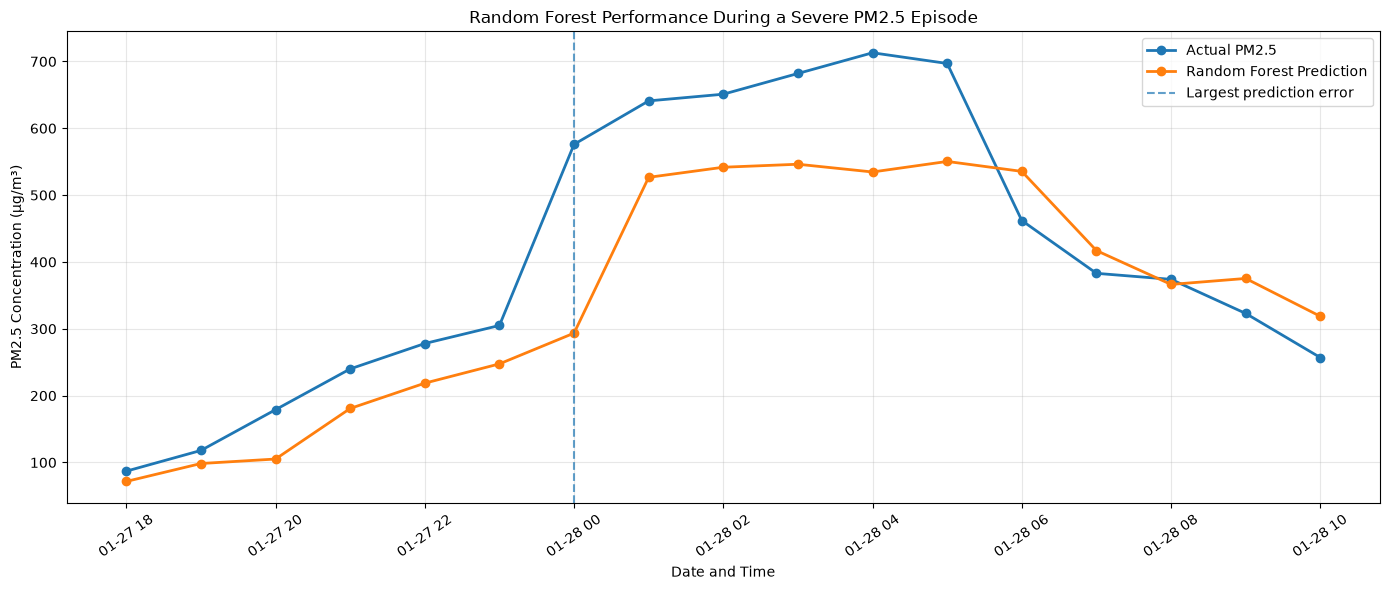

In [119]:
plt.figure(figsize=(14, 6))

plt.plot(
    event_df.index,
    event_df["Actual"],
    marker="o",
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    event_df.index,
    event_df["Predicted"],
    marker="o",
    label="Random Forest Prediction",
    linewidth=2
)

plt.axvline(
    pd.Timestamp("2017-01-28 00:00:00"),
    linestyle="--",
    alpha=0.7,
    label="Largest prediction error"
)

plt.title("Random Forest Performance During a Severe PM2.5 Episode")
plt.xlabel("Date and Time")
plt.ylabel("PM2.5 Concentration (µg/m³)")
plt.legend()
plt.xticks(rotation=35)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

compare against persistence during this exact episode

In [120]:
# Compare both models during the January 27–28 episode
event_actual = event_df["Actual"]

event_persistence = forecast_df.loc[
    event_actual.index, "PM2.5"
]

event_comparison = pd.DataFrame({
    "Actual": event_actual,
    "Random Forest": event_df["Predicted"],
    "Persistence": event_persistence
}).dropna()

event_metrics = pd.DataFrame({
    "Model": ["Random Forest", "Persistence"],
    "MAE": [
        mean_absolute_error(
            event_comparison["Actual"],
            event_comparison["Random Forest"]
        ),
        mean_absolute_error(
            event_comparison["Actual"],
            event_comparison["Persistence"]
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            event_comparison["Actual"],
            event_comparison["Random Forest"]
        )),
        np.sqrt(mean_squared_error(
            event_comparison["Actual"],
            event_comparison["Persistence"]
        ))
    ]
})

print("Episode observations:", len(event_comparison))
print(event_metrics.round(2).to_string(index=False))

Episode observations: 17
        Model   MAE   RMSE
Random Forest 87.11 110.11
  Persistence 65.18  96.92


Identify high-pollution episodes in the test set

In [121]:
# Identify high-pollution episodes in the test set

episode_df = pd.DataFrame({
    "Actual": y_test_model,
    "Random Forest": test_predictions
}, index=y_test_model.index).sort_index()

# Add current-hour PM2.5 for the persistence baseline
episode_df["Persistence"] = forecast_df.loc[
    episode_df.index, "PM2.5"
]

# Flag high-pollution observations
episode_df["High Pollution"] = episode_df["Actual"] > 150

# Start a new episode when:
# 1. A high-pollution run begins after a lower reading, or
# 2. The time gap between observations exceeds one hour.
time_gap = episode_df.index.to_series().diff()
new_episode = (
    episode_df["High Pollution"]
    & (
        ~episode_df["High Pollution"].shift(
            1, fill_value=False
        )
        | (time_gap > pd.Timedelta(hours=1))
    )
)

episode_df["Episode ID"] = (
    new_episode.cumsum()
    .where(episode_df["High Pollution"])
)

print("Test observations:", len(episode_df))
print("High-pollution observations:",
      int(episode_df["High Pollution"].sum()))
print("High-pollution episodes:",
      int(episode_df["Episode ID"].nunique()))

print("\nFirst few high-pollution observations:")
print(
    episode_df.loc[
        episode_df["High Pollution"],
        ["Actual", "Random Forest", "Persistence", "Episode ID"]
    ].head(10).round(2).to_string()
)

Test observations: 5225
High-pollution observations: 1020
High-pollution episodes: 81

First few high-pollution observations:
                     Actual  Random Forest  Persistence  Episode ID
datetime                                                           
2016-07-30 07:00:00   162.0         129.48        130.0         1.0
2016-07-30 08:00:00   208.0         164.68        162.0         1.0
2016-07-30 09:00:00   216.5         209.37        208.0         1.0
2016-07-30 10:00:00   225.0         215.02        216.5         1.0
2016-07-30 11:00:00   228.0         220.86        225.0         1.0
2016-07-30 12:00:00   219.0         214.20        228.0         1.0
2016-07-30 13:00:00   226.0         207.16        219.0         1.0
2016-07-30 14:00:00   235.0         223.98        226.0         1.0
2016-07-30 15:00:00   223.0         227.27        235.0         1.0
2016-07-30 16:00:00   227.0         215.21        223.0         1.0


Compare both models episode by episode

In [122]:
# Compare Random Forest and persistence for each episode

episode_rows = []

for episode_id, group in episode_df.dropna(
    subset=["Episode ID"]
).groupby("Episode ID"):

    # Ensure a fair comparison on identical timestamps
    group = group.dropna(
        subset=["Actual", "Random Forest", "Persistence"]
    )

    if len(group) == 0:
        continue

    actual = group["Actual"]
    rf_pred = group["Random Forest"]
    persistence_pred = group["Persistence"]

    rf_mae = mean_absolute_error(actual, rf_pred)
    rf_rmse = np.sqrt(mean_squared_error(actual, rf_pred))

    persistence_mae = mean_absolute_error(
        actual, persistence_pred
    )
    persistence_rmse = np.sqrt(mean_squared_error(
        actual, persistence_pred
    ))

    episode_rows.append({
        "Episode ID": int(episode_id),
        "Start": group.index.min(),
        "End": group.index.max(),
        "Samples": len(group),
        "Peak PM2.5": actual.max(),
        "RF MAE": rf_mae,
        "Persistence MAE": persistence_mae,
        "RF RMSE": rf_rmse,
        "Persistence RMSE": persistence_rmse
    })

episode_metrics = pd.DataFrame(episode_rows)

episode_metrics["RF wins MAE"] = (
    episode_metrics["RF MAE"]
    < episode_metrics["Persistence MAE"]
)

episode_metrics["RF wins RMSE"] = (
    episode_metrics["RF RMSE"]
    < episode_metrics["Persistence RMSE"]
)

print("Episodes evaluated:", len(episode_metrics))
print(
    "RF wins on MAE:",
    int(episode_metrics["RF wins MAE"].sum())
)
print(
    "RF wins on RMSE:",
    int(episode_metrics["RF wins RMSE"].sum())
)

print("\nFirst 15 episode comparisons:")
print(
    episode_metrics.head(15).round(2).to_string(index=False)
)

Episodes evaluated: 81
RF wins on MAE: 40
RF wins on RMSE: 38

First 15 episode comparisons:
 Episode ID               Start                 End  Samples  Peak PM2.5  RF MAE  Persistence MAE  RF RMSE  Persistence RMSE  RF wins MAE  RF wins RMSE
          1 2016-07-30 07:00:00 2016-07-30 16:00:00       10       235.0   15.08            13.90    19.47             19.14        False         False
          2 2016-08-04 09:00:00 2016-08-04 10:00:00        2       156.0   12.71             9.50    15.44             11.51        False         False
          3 2016-09-14 09:00:00 2016-09-14 10:00:00        2       157.0    8.36             4.50     9.42              5.70        False         False
          4 2016-09-15 21:00:00 2016-09-16 01:00:00        5       190.0   12.15            14.00    14.07             15.22         True          True
          5 2016-09-16 04:00:00 2016-09-16 04:00:00        1       152.0   26.97            31.00    26.97             31.00         True          

C:\Users\HP\AppData\Local\Temp\ipykernel_12772\4073072953.py:67: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  episode_metrics.head(15).round(2).to_string(index=False)


Calculate overall performance during high pollution

In [123]:
# Pooled performance across all high-pollution observations

high_df = episode_df.loc[
    episode_df["High Pollution"]
].dropna(
    subset=["Actual", "Random Forest", "Persistence"]
)

actual = high_df["Actual"]
rf_pred = high_df["Random Forest"]
persistence_pred = high_df["Persistence"]

pooled_results = pd.DataFrame({
    "Model": ["Random Forest", "Persistence"],
    "MAE": [
        mean_absolute_error(actual, rf_pred),
        mean_absolute_error(actual, persistence_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, rf_pred)),
        np.sqrt(mean_squared_error(actual, persistence_pred))
    ],
    "R²": [
        r2_score(actual, rf_pred),
        r2_score(actual, persistence_pred)
    ]
})

print("High-pollution observations compared:", len(high_df))
print("\nPooled model performance:")
print(pooled_results.round(3).to_string(index=False))

print("\nEpisode duration summary (hours):")
print(
    episode_metrics["Samples"]
    .describe()
    .round(2)
    .to_string()
)

print("\nLongest episodes:")
print(
    episode_metrics.nlargest(5, "Samples")[
        ["Episode ID", "Start", "End", "Samples",
         "Peak PM2.5", "RF MAE", "Persistence MAE"]
    ].to_string(index=False)
)

High-pollution observations compared: 1020

Pooled model performance:
        Model    MAE   RMSE    R²
Random Forest 21.785 33.939 0.852
  Persistence 20.710 33.077 0.860

Episode duration summary (hours):
count     81.00
mean      12.59
std       19.66
min        1.00
25%        2.00
50%        5.00
75%       13.00
max      111.00

Longest episodes:
 Episode ID               Start                 End  Samples  Peak PM2.5    RF MAE  Persistence MAE
         51 2016-12-17 11:00:00 2016-12-22 01:00:00      111       440.0 24.697672        21.549550
         64 2017-01-02 21:00:00 2017-01-07 08:00:00      108       500.0 26.963840        24.583333
         20 2016-10-13 11:00:00 2016-10-16 00:00:00       62       346.0 16.641708        16.354839
         24 2016-11-03 11:00:00 2016-11-05 04:00:00       42       334.0 15.119034        16.500000
         48 2016-12-11 10:00:00 2016-12-13 03:00:00       42       257.0 14.990425        15.380952


Examine performance as pollution rises

In [124]:
# Compare models across actual PM2.5 concentration bands

regime_df = episode_df.dropna(
    subset=["Actual", "Random Forest", "Persistence"]
).copy()

regime_df["Pollution Band"] = pd.cut(
    regime_df["Actual"],
    bins=[-np.inf, 35, 75, 150, 250, np.inf],
    labels=[
        "Low (≤35)",
        "Moderate (35–75)",
        "High (75–150)",
        "Very high (150–250)",
        "Extreme (>250)"
    ],
    right=True
)

regime_rows = []

for band, group in regime_df.groupby(
    "Pollution Band", observed=True
):
    actual = group["Actual"]
    rf_pred = group["Random Forest"]
    persistence_pred = group["Persistence"]

    regime_rows.append({
        "Pollution Band": str(band),
        "Samples": len(group),
        "RF MAE": mean_absolute_error(actual, rf_pred),
        "Persistence MAE": mean_absolute_error(
            actual, persistence_pred
        ),
        "RF RMSE": np.sqrt(
            mean_squared_error(actual, rf_pred)
        ),
        "Persistence RMSE": np.sqrt(
            mean_squared_error(actual, persistence_pred)
        )
    })

regime_metrics = pd.DataFrame(regime_rows)

print(regime_metrics.round(2).to_string(index=False))

     Pollution Band  Samples  RF MAE  Persistence MAE  RF RMSE  Persistence RMSE
          Low (≤35)     2093    5.45             5.59    11.81             12.86
   Moderate (35–75)     1023    9.35             9.70    14.53             15.70
      High (75–150)     1087   12.85            13.28    20.80             22.28
Very high (150–250)      690   17.79            17.93    27.14             28.55
     Extreme (>250)      330   30.14            26.52    44.94             40.96


Check whether extreme pollution is being underpredicted

In [125]:
# Investigate prediction bias during extreme pollution

extreme_df = regime_df.loc[
    regime_df["Actual"] > 250
].copy()

extreme_df["RF Signed Error"] = (
    extreme_df["Random Forest"] - extreme_df["Actual"]
)

extreme_df["Persistence Signed Error"] = (
    extreme_df["Persistence"] - extreme_df["Actual"]
)

for model_name, error_col in [
    ("Random Forest", "RF Signed Error"),
    ("Persistence", "Persistence Signed Error")
]:
    errors = extreme_df[error_col]

    print(f"\n{model_name}")
    print("Mean signed error:", round(errors.mean(), 2))
    print(
        "Underprediction frequency:",
        f"{(errors < 0).mean() * 100:.1f}%"
    )
    print(
        "Overprediction frequency:",
        f"{(errors > 0).mean() * 100:.1f}%"
    )

print("\nLargest Random Forest errors in the extreme band:")
extreme_df["RF Absolute Error"] = (
    extreme_df["RF Signed Error"].abs()
)

print(
    extreme_df.nlargest(10, "RF Absolute Error")[
        ["Actual", "Random Forest", "Persistence",
         "RF Signed Error", "Persistence Signed Error"]
    ].round(2).to_string()
)


Random Forest
Mean signed error: -15.12
Underprediction frequency: 69.7%
Overprediction frequency: 30.3%

Persistence
Mean signed error: -6.15
Underprediction frequency: 55.8%
Overprediction frequency: 41.5%

Largest Random Forest errors in the extreme band:
                     Actual  Random Forest  Persistence  RF Signed Error  Persistence Signed Error
datetime                                                                                          
2017-01-28 00:00:00   576.0         293.54        305.0          -282.46                    -271.0
2017-01-28 04:00:00   713.0         534.63        682.0          -178.37                     -31.0
2016-12-31 14:00:00   379.0         218.20        214.0          -160.80                    -165.0
2017-01-28 05:00:00   697.0         550.40        713.0          -146.60                      16.0
2017-01-04 09:00:00   441.0         294.83        338.0          -146.17                    -103.0
2016-12-20 00:00:00   365.0         219.21     

Train the weighted Random Forest

In [126]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np
import pandas as pd

# Give additional weight to higher PM2.5 training targets
weighted_train = X_train_model.copy()

sample_weights = np.ones(len(y_train_model), dtype=float)

sample_weights[y_train_model >= 75] = 2.0
sample_weights[y_train_model >= 150] = 4.0
sample_weights[y_train_model >= 250] = 6.0

print("Training samples:", len(y_train_model))
print("Sample-weight distribution:")
print(
    pd.Series(sample_weights)
    .value_counts()
    .sort_index()
    .rename_axis("Weight")
    .rename("Samples")
    .to_string()
)

# Train a second model with the same hyperparameters
rf_weighted = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_weighted.fit(
    X_train_model,
    y_train_model,
    sample_weight=sample_weights
)

print("\nWeighted Random Forest trained successfully.")

Training samples: 24034
Sample-weight distribution:
Weight
1.0    13764
2.0     6305
4.0     2838
6.0     1127

Weighted Random Forest trained successfully.


Evaluate both Random Forest models

In [127]:
# Predict on the same test observations
weighted_predictions = rf_weighted.predict(X_test_model)

# Compare original and weighted Random Forest on identical timestamps
model_comparison_df = pd.DataFrame({
    "Actual": y_test_model,
    "Original RF": test_predictions,
    "Weighted RF": weighted_predictions,
    "Persistence": forecast_df.loc[
        y_test_model.index, "PM2.5"
    ]
}, index=y_test_model.index)

# Keep rows with all predictions available
model_comparison_df = model_comparison_df.dropna()

# Create evaluation bands from actual next-hour PM2.5
model_comparison_df["Pollution Band"] = pd.cut(
    model_comparison_df["Actual"],
    bins=[-np.inf, 35, 75, 150, 250, np.inf],
    labels=[
        "Low (≤35)",
        "Moderate (35–75)",
        "High (75–150)",
        "Very high (150–250)",
        "Extreme (>250)"
    ]
)

comparison_rows = []

for band, group in model_comparison_df.groupby(
    "Pollution Band", observed=True
):
    actual = group["Actual"]

    for model_name in [
        "Original RF", "Weighted RF", "Persistence"
    ]:
        pred = group[model_name]

        comparison_rows.append({
            "Pollution Band": str(band),
            "Model": model_name,
            "Samples": len(group),
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred))
        })

band_comparison = pd.DataFrame(comparison_rows)

print("Model comparison by pollution band:")
print(
    band_comparison.round(2).to_string(index=False)
)

Model comparison by pollution band:
     Pollution Band       Model  Samples   MAE  RMSE
          Low (≤35) Original RF     2093  5.45 11.81
          Low (≤35) Weighted RF     2093  5.73 13.13
          Low (≤35) Persistence     2093  5.59 12.86
   Moderate (35–75) Original RF     1023  9.35 14.53
   Moderate (35–75) Weighted RF     1023 10.39 17.26
   Moderate (35–75) Persistence     1023  9.70 15.70
      High (75–150) Original RF     1087 12.85 20.80
      High (75–150) Weighted RF     1087 12.76 21.38
      High (75–150) Persistence     1087 13.28 22.28
Very high (150–250) Original RF      690 17.79 27.14
Very high (150–250) Weighted RF      690 17.26 26.20
Very high (150–250) Persistence      690 17.93 28.55
     Extreme (>250) Original RF      330 30.14 44.94
     Extreme (>250) Weighted RF      330 31.92 47.43
     Extreme (>250) Persistence      330 26.52 40.96


In [128]:
# Examine one-hour PM2.5 changes in the training data

change_df = pd.DataFrame({
    "Current PM2.5": forecast_df.loc[
        y_train_model.index, "PM2.5"
    ],
    "Next-hour PM2.5": y_train_model
}).dropna()

change_df["PM2.5 Change"] = (
    change_df["Next-hour PM2.5"]
    - change_df["Current PM2.5"]
)

print("Training observations with both readings:", len(change_df))
print("\nOne-hour PM2.5 change statistics:")
print(change_df["PM2.5 Change"].describe().round(2).to_string())

print("\nLargest increases:")
print(
    change_df.nlargest(5, "PM2.5 Change").round(2).to_string()
)

print("\nLargest decreases:")
print(
    change_df.nsmallest(5, "PM2.5 Change").round(2).to_string()
)

Training observations with both readings: 24016

One-hour PM2.5 change statistics:
count    24016.00
mean         0.02
std         20.51
min       -341.00
25%         -5.00
50%          1.00
75%          6.00
max        468.00

Largest increases:
                     Current PM2.5  Next-hour PM2.5  PM2.5 Change
datetime                                                         
2013-05-16 10:00:00          197.0            665.0         468.0
2014-06-24 16:00:00            3.0            463.0         460.0
2015-04-16 05:00:00           65.0            403.0         338.0
2013-05-04 22:00:00           84.0            366.0         282.0
2014-10-09 17:00:00          178.0            446.0         268.0

Largest decreases:
                     Current PM2.5  Next-hour PM2.5  PM2.5 Change
datetime                                                         
2015-11-30 10:00:00          344.0              3.0        -341.0
2015-04-16 06:00:00          403.0             64.0        -339.0
2013-05

Train a change-based Random Forest

In [129]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Build training data for predicting the hourly change
change_train = pd.DataFrame(index=y_train_model.index)

change_train["Current PM2.5"] = forecast_df.loc[
    y_train_model.index, "PM2.5"
]

change_train["Next-hour PM2.5"] = y_train_model
change_train = change_train.dropna()

# Use the same predictors as the original model
X_change_train = X_train_model.loc[change_train.index]
y_change_train = (
    change_train["Next-hour PM2.5"]
    - change_train["Current PM2.5"]
)

print("Change-model training samples:", len(X_change_train))
print("Predictor count:", X_change_train.shape[1])

# Train the model to predict change rather than absolute PM2.5
rf_change = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_change.fit(X_change_train, y_change_train)

print("Change-based Random Forest trained successfully.")

Change-model training samples: 24016
Predictor count: 20
Change-based Random Forest trained successfully.


Evaluate the change-based model

In [130]:
# Predict the next-hour change on the test set
change_test = pd.DataFrame(index=y_test_model.index)

change_test["Current PM2.5"] = forecast_df.loc[
    y_test_model.index, "PM2.5"
]

change_test["Actual"] = y_test_model
change_test = change_test.dropna()

X_change_test = X_test_model.loc[change_test.index]

predicted_change = rf_change.predict(X_change_test)

# Convert predicted changes back to PM2.5 forecasts
change_predictions = (
    change_test["Current PM2.5"].to_numpy()
    + predicted_change
)

actual = change_test["Actual"].to_numpy()

comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Weighted Random Forest",
        "Change-based Random Forest",
        "Persistence baseline"
    ],
    "MAE": [
        mean_absolute_error(actual, test_predictions[
            y_test_model.index.get_indexer(change_test.index)
        ]),
        mean_absolute_error(actual, weighted_predictions[
            y_test_model.index.get_indexer(change_test.index)
        ]),
        mean_absolute_error(actual, change_predictions),
        mean_absolute_error(
            actual, change_test["Current PM2.5"].to_numpy()
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, test_predictions[
            y_test_model.index.get_indexer(change_test.index)
        ])),
        np.sqrt(mean_squared_error(actual, weighted_predictions[
            y_test_model.index.get_indexer(change_test.index)
        ])),
        np.sqrt(mean_squared_error(actual, change_predictions)),
        np.sqrt(mean_squared_error(
            actual, change_test["Current PM2.5"].to_numpy()
        ))
    ],
    "R²": [
        r2_score(actual, test_predictions[
            y_test_model.index.get_indexer(change_test.index)
        ]),
        r2_score(actual, weighted_predictions[
            y_test_model.index.get_indexer(change_test.index)
        ]),
        r2_score(actual, change_predictions),
        r2_score(actual, change_test["Current PM2.5"].to_numpy())
    ]
})

print("Common test observations:", len(change_test))
print(comparison.round(4).to_string(index=False))

Common test observations: 5223
                     Model     MAE    RMSE     R²
    Original Random Forest 10.9444 20.3019 0.9525
    Weighted Random Forest 11.2833 21.3406 0.9475
Change-based Random Forest 10.9091 20.2310 0.9528
      Persistence baseline 10.9502 20.7748 0.9503


Evaluate all models on extreme-pollution observations

In [131]:
# Compare models specifically when actual PM2.5 exceeds 250 µg/m³

extreme_mask = actual > 250

extreme_actual = actual[extreme_mask]
extreme_current = change_test["Current PM2.5"].to_numpy()[
    extreme_mask
]

extreme_predictions = {
    "Original Random Forest": test_predictions[
        y_test_model.index.get_indexer(change_test.index)
    ][extreme_mask],
    "Weighted Random Forest": weighted_predictions[
        y_test_model.index.get_indexer(change_test.index)
    ][extreme_mask],
    "Change-based Random Forest": change_predictions[
        extreme_mask
    ],
    "Persistence baseline": extreme_current
}

extreme_comparison = []

for model_name, pred in extreme_predictions.items():
    errors = pred - extreme_actual

    extreme_comparison.append({
        "Model": model_name,
        "Samples": len(extreme_actual),
        "MAE": mean_absolute_error(extreme_actual, pred),
        "RMSE": np.sqrt(mean_squared_error(extreme_actual, pred)),
        "Mean Signed Error": errors.mean(),
        "Underprediction (%)": (errors < 0).mean() * 100
    })

extreme_comparison = pd.DataFrame(extreme_comparison)

print(extreme_comparison.round(2).to_string(index=False))

                     Model  Samples   MAE  RMSE  Mean Signed Error  Underprediction (%)
    Original Random Forest      330 30.14 44.94             -15.12                69.70
    Weighted Random Forest      330 31.92 47.43             -14.94                67.58
Change-based Random Forest      330 29.00 43.48             -15.38                69.70
      Persistence baseline      330 26.52 40.96              -6.15                55.76


Check whether the change-based model is better across each concentration band

In [132]:
# Compare original, change-based, and persistence models by pollution band

common_results = pd.DataFrame({
    "Actual": actual,
    "Original RF": test_predictions[
        y_test_model.index.get_indexer(change_test.index)
    ],
    "Change-based RF": change_predictions,
    "Persistence": change_test["Current PM2.5"].to_numpy()
}, index=change_test.index)

common_results["Pollution Band"] = pd.cut(
    common_results["Actual"],
    bins=[-np.inf, 35, 75, 150, 250, np.inf],
    labels=[
        "Low (≤35)",
        "Moderate (35–75)",
        "High (75–150)",
        "Very high (150–250)",
        "Extreme (>250)"
    ]
)

rows = []

for band, group in common_results.groupby(
    "Pollution Band", observed=True
):
    for model_name in [
        "Original RF", "Change-based RF", "Persistence"
    ]:
        rows.append({
            "Pollution Band": str(band),
            "Model": model_name,
            "Samples": len(group),
            "MAE": mean_absolute_error(
                group["Actual"], group[model_name]
            ),
            "RMSE": np.sqrt(mean_squared_error(
                group["Actual"], group[model_name]
            ))
        })

band_final_comparison = pd.DataFrame(rows)

print(band_final_comparison.round(2).to_string(index=False))

     Pollution Band           Model  Samples   MAE  RMSE
          Low (≤35)     Original RF     2093  5.45 11.81
          Low (≤35) Change-based RF     2093  5.31 11.63
          Low (≤35)     Persistence     2093  5.59 12.86
   Moderate (35–75)     Original RF     1023  9.35 14.53
   Moderate (35–75) Change-based RF     1023  9.10 14.11
   Moderate (35–75)     Persistence     1023  9.70 15.70
      High (75–150)     Original RF     1087 12.85 20.80
      High (75–150) Change-based RF     1087 13.02 20.72
      High (75–150)     Persistence     1087 13.28 22.28
Very high (150–250)     Original RF      690 17.79 27.14
Very high (150–250) Change-based RF      690 18.58 28.51
Very high (150–250)     Persistence      690 17.93 28.55
     Extreme (>250)     Original RF      330 30.14 44.94
     Extreme (>250) Change-based RF      330 29.00 43.48
     Extreme (>250)     Persistence      330 26.52 40.96


save the comparison results

In [133]:
from pathlib import Path

results_dir = Path(r"C:\UrbanPulse-AI\reports")
results_dir.mkdir(parents=True, exist_ok=True)

# Save overall test-set comparison
comparison.to_csv(
    results_dir / "overall_model_comparison.csv",
    index=False
)

# Save band-by-band comparison
band_final_comparison.to_csv(
    results_dir / "pollution_band_model_comparison.csv",
    index=False
)

# Save extreme-pollution comparison
extreme_comparison.to_csv(
    results_dir / "extreme_pollution_model_comparison.csv",
    index=False
)

print("Saved model comparison files to:", results_dir)
print("1. overall_model_comparison.csv")
print("2. pollution_band_model_comparison.csv")
print("3. extreme_pollution_model_comparison.csv")

Saved model comparison files to: C:\UrbanPulse-AI\reports
1. overall_model_comparison.csv
2. pollution_band_model_comparison.csv
3. extreme_pollution_model_comparison.csv


Plot the comparison

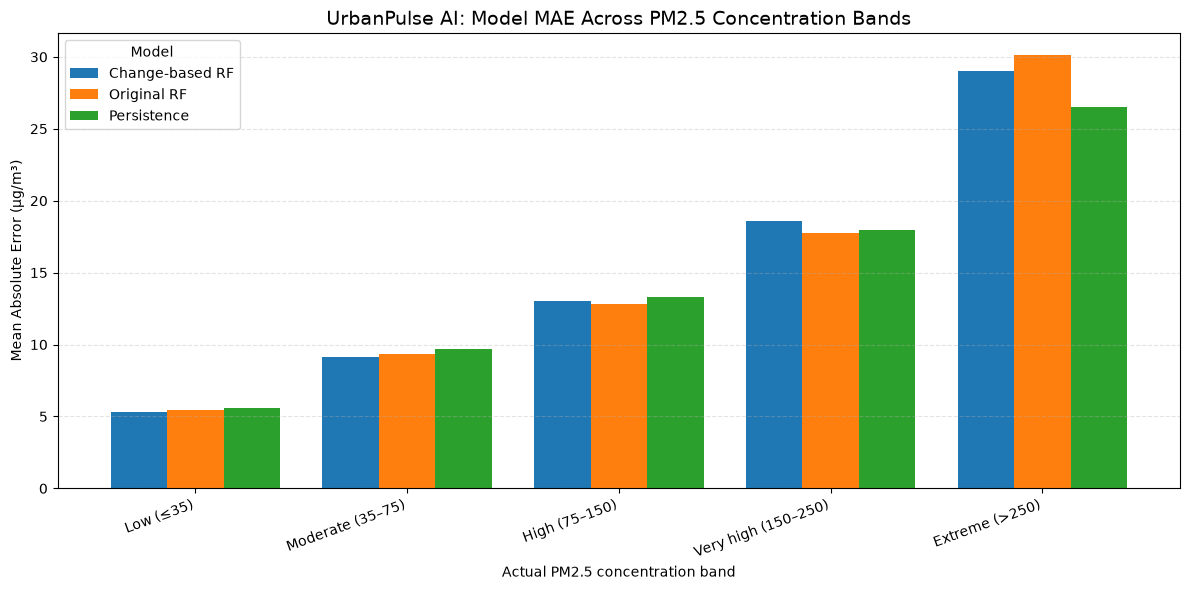

Chart saved to: C:\UrbanPulse-AI\reports\pollution_band_mae_comparison.png


In [134]:
import matplotlib.pyplot as plt

# Prepare the band-by-band MAE comparison
mae_plot_data = band_final_comparison.pivot(
    index="Pollution Band",
    columns="Model",
    values="MAE"
)

# Keep bands in concentration order
band_order = [
    "Low (≤35)",
    "Moderate (35–75)",
    "High (75–150)",
    "Very high (150–250)",
    "Extreme (>250)"
]

mae_plot_data = mae_plot_data.reindex(band_order)

ax = mae_plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title(
    "UrbanPulse AI: Model MAE Across PM2.5 Concentration Bands",
    fontsize=14
)
ax.set_xlabel("Actual PM2.5 concentration band")
ax.set_ylabel("Mean Absolute Error (µg/m³)")
ax.legend(title="Model")
ax.grid(axis="y", linestyle="--", alpha=0.35)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

# Save a high-resolution copy for your report or portfolio
chart_path = results_dir / "pollution_band_mae_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)

Document the experimental setup

In [135]:
from pathlib import Path
from datetime import datetime

reports_dir = Path(r"C:\UrbanPulse-AI\reports")
reports_dir.mkdir(parents=True, exist_ok=True)

methodology = f"""
# UrbanPulse AI — Forecasting Experiment Record

## Dataset
- Source: UCI Beijing Multi-Site Air Quality dataset
- Station analyzed: Aotizhongxin
- Raw station records: {len(station_df):,}
- Time range: {station_df.index.min()} to {station_df.index.max()}
- Forecast horizon: One hour ahead

## Target
- Target variable: PM2.5 at the next hour
- Target construction: PM2.5 shifted by -1 hour
- Training target observations: {len(y_train_model):,}
- Validation target observations: {int(y_val.notna().sum()):,}
- Test target observations: {int(y_test.notna().sum()):,}

## Chronological Split
- Training period: {X_train.index.min()} to {X_train.index.max()}
- Validation period: {X_val.index.min()} to {X_val.index.max()}
- Test period: {X_test.index.min()} to {X_test.index.max()}
- Predictors: {X_train_model.shape[1]}

## Models Evaluated
1. Persistence baseline: current-hour PM2.5 used as the next-hour forecast.
2. Original Random Forest: 100 trees, maximum depth 20, minimum leaf size 2.
3. Weighted Random Forest: same hyperparameters, with training sample weights
   increased for higher next-hour PM2.5 values.
4. Change-based Random Forest: predicts the one-hour PM2.5 change and adds
   the predicted change to current-hour PM2.5.

## Evaluation
- Metrics: MAE, RMSE, and R-squared.
- Additional analysis: performance by observed PM2.5 concentration band,
  extreme-pollution error bias, and individual high-pollution episodes.
- Exploratory extreme-pollution threshold: actual next-hour PM2.5 > 250 µg/m³.
- The concentration bands are analytical groupings, not official health categories.

## Important Limitation
The test set was examined repeatedly during exploratory model comparisons.
Therefore, these results should not be treated as a completely untouched
final estimate after model selection. Further tuning should use training
and validation data, followed by evaluation on a fresh or otherwise
untouched chronological test period.

## Recorded
{datetime.now().strftime("%Y-%m-%d %H:%M")}
"""

methodology_path = reports_dir / "forecasting_methodology.md"
methodology_path.write_text(methodology.strip() + "\n", encoding="utf-8")

print("Methodology record saved:")
print(methodology_path)
print("\nKey setup:")
print("Station: Aotizhongxin")
print("Predictors:", X_train_model.shape[1])
print("Training samples:", len(y_train_model))
print("Validation targets:", int(y_val.notna().sum()))
print("Test targets:", int(y_test.notna().sum()))

Methodology record saved:
C:\UrbanPulse-AI\reports\forecasting_methodology.md

Key setup:
Station: Aotizhongxin
Predictors: 20
Training samples: 24034
Validation targets: 5217
Test targets: 5225


Audit the reports folder

In [136]:
from pathlib import Path

reports_dir = Path(r"C:\UrbanPulse-AI\reports")

expected_files = [
    "overall_model_comparison.csv",
    "pollution_band_model_comparison.csv",
    "extreme_pollution_model_comparison.csv",
    "pollution_band_mae_comparison.png",
    "forecasting_methodology.md",
]

print("UrbanPulse AI — Report Artifact Audit\n")

for filename in expected_files:
    path = reports_dir / filename

    if path.exists():
        size_kb = path.stat().st_size / 1024
        print(f"[OK] {filename} — {size_kb:.1f} KB")
    else:
        print(f"[MISSING] {filename}")

print("\nTotal files in reports folder:", len(list(reports_dir.iterdir())))

UrbanPulse AI — Report Artifact Audit

[OK] overall_model_comparison.csv — 0.3 KB
[OK] pollution_band_model_comparison.csv — 1.1 KB
[OK] extreme_pollution_model_comparison.csv — 0.5 KB
[OK] pollution_band_mae_comparison.png — 156.7 KB
[OK] forecasting_methodology.md — 1.8 KB

Total files in reports folder: 5


Inspect the project structure

In [137]:
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")

for folder in ["data", "notebooks", "src", "models", "reports"]:
    folder_path = project_dir / folder
    print(f"\n{folder}/")

    if not folder_path.exists():
        print("  (folder not found)")
        continue

    for path in sorted(folder_path.iterdir()):
        if path.is_dir():
            print(f"  {path.name}/")
        else:
            print(f"  {path.name}")


data/
  interim/
  processed/
  raw/

notebooks/

src/
  __init__.py
  data/
  evaluation/
  features/
  models/
  visualization/

models/

reports/
  extreme_pollution_model_comparison.csv
  forecasting_methodology.md
  overall_model_comparison.csv
  pollution_band_mae_comparison.png
  pollution_band_model_comparison.csv


Create the project README

In [140]:

from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
readme_path = project_dir / "README.md"

readme_lines = [
    "# UrbanPulse AI",
    "",
    "### Intelligent Air Quality Analysis & One-Hour-Ahead PM2.5 Forecasting",
    "",
    "UrbanPulse AI is an end-to-end data science project exploring how historical air-quality measurements, meteorological conditions, and temporal patterns can support short-term PM2.5 forecasting. It combines exploratory data analysis, feature engineering, machine learning, baseline comparisons, and pollution-level error analysis.",
    "",
    "The goal is not simply to produce a prediction, but to understand when a model performs well, where its errors increase, and why forecasting extreme pollution remains challenging.",
    "",
    "---",
    "",
    "## Project Highlights",
    "",
    "- **Air quality exploration:** Analyze pollutant distributions, hourly patterns, seasonal changes, and weather relationships.",
    "- **Time-aware forecasting:** Predict PM2.5 concentration one hour ahead using a chronological evaluation strategy.",
    "- **Feature engineering:** Use temporal and cyclical features alongside pollutant and meteorological variables.",
    "- **Model comparison:** Evaluate direct Random Forest, weighted Random Forest, change-based Random Forest, and a persistence baseline.",
    "- **Error investigation:** Compare performance across concentration bands and examine high-pollution episodes.",
    "- **Reproducible reporting:** Save evaluation tables, a comparison chart, and the experimental methodology.",
    "",
    "## Dataset",
    "",
    "This project uses the [Beijing Multi-Site Air Quality dataset from the UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data). The current modeling experiments focus on the **Aotizhongxin monitoring station**, with hourly observations from March 2013 through February 2017.",
    "",
    "The dataset includes:",
    "- **Pollutants:** PM2.5, PM10, SO2, NO2, CO, and O3.",
    "- **Meteorological measurements:** Temperature, pressure, dew point, rainfall, and wind speed.",
    "- **Temporal information:** Hour, day of the week, and month.",
    "",
    "The results describe this station and historical period; they should not automatically be generalized to other locations or time periods.",
    "",
    "## Forecasting Objective",
    "",
    "**Task:** Estimate PM2.5 concentration at the next hour.",
    "",
    "The target is created by shifting the observed PM2.5 series one hour into the future. The prediction is evaluated against that next-hour observation, while the persistence baseline uses the current-hour PM2.5 reading as its forecast.",
    "",
    "### Workflow",
    "",
    "1. Inspect the dataset and assess missing observations.",
    "2. Clean and prepare the station-level time series.",
    "3. Explore pollutant distributions, hourly patterns, seasonal variation, and weather relationships.",
    "4. Engineer temporal and cyclical predictors.",
    "5. Split the data chronologically into training, validation, and test periods.",
    "6. Fit median imputation on training predictors and apply it to subsequent partitions.",
    "7. Train and compare forecasting models.",
    "8. Evaluate overall performance and investigate errors at higher PM2.5 concentrations.",
    "",
    "Chronological splitting helps assess forecasting on later observations without randomly mixing past and future records.",
    "",
    "## Models Evaluated",
    "",
    "| Model | Approach |",
    "|---|---|",
    "| Persistence baseline | Uses current-hour PM2.5 as the next-hour forecast. |",
    "| Original Random Forest | Predicts next-hour PM2.5 directly. |",
    "| Weighted Random Forest | Uses larger training weights for higher PM2.5 targets. |",
    "| Change-based Random Forest | Predicts the next-hour change in PM2.5 and adds it to the current reading. |",
    "",
    "The Random Forest experiments used 100 trees, a maximum depth of 20, and a minimum leaf size of 2. The weighted model used target-based sample weights; the change-based model learned the difference between consecutive PM2.5 readings.",
    "",
    "## Test Results",
    "",
    "The following results were calculated on **5,223 common test timestamps**, enabling a like-for-like comparison across the three models.",
    "",
    "| Model | MAE (µg/m³) | RMSE (µg/m³) | R² |",
    "|---|---:|---:|---:|",
    "| Original Random Forest | 10.944 | 20.302 | 0.9525 |",
    "| Change-based Random Forest | 10.909 | 20.231 | 0.9528 |",
    "| Persistence baseline | 10.950 | 20.775 | 0.9503 |",
    "",
    "- **MAE** measures the average absolute prediction error.",
    "- **RMSE** penalizes larger errors more heavily.",
    "- **R²** measures the proportion of target variance explained relative to a mean-prediction reference.",
    "",
    "### What the Results Tell Us",
    "",
    "The change-based Random Forest achieved the best overall RMSE among these three models, but its improvement over the original Random Forest was small. The persistence baseline was also competitive, showing how difficult it can be to improve on the strong short-term continuity of air-quality measurements.",
    "",
    "Overall metrics alone do not tell the full story. Model performance changes with pollution concentration, and the model with the best average score is not necessarily the best choice during an extreme pollution episode.",
    "",
    "## High-Pollution Error Analysis",
    "",
    "Test observations were grouped into exploratory PM2.5 concentration bands to investigate how prediction errors changed as pollution increased.",
    "",
    "- Errors generally became larger at higher concentrations.",
    "- The change-based model improved on the original Random Forest in the extreme band above 250 µg/m³.",
    "- The persistence baseline nevertheless performed better than both Random Forest variants in that extreme band.",
    "- Random Forest predictions tended to underestimate some of the highest observed concentrations.",
    "",
    "These results highlight a key forecasting challenge: accurately following rapid rises and peaks can be more difficult than predicting ordinary concentration changes.",
    "",
    "The concentration bands are analytical groupings for this project, not official health categories. This analysis is not a validated pollution-alert system.",
    "",
    "## Visual Results",
    "",
    "The following chart compares model MAE across the analyzed pollution bands:",
    "",
    "![Model MAE comparison by PM2.5 concentration band](reports/pollution_band_mae_comparison.png)",
    "",
    "## Repository Structure",
    "",
    "```text",
    "UrbanPulse-AI/",
    "├── data/",
    "│   ├── raw/",
    "│   ├── interim/",
    "│   └── processed/",
    "├── notebooks/",
    "├── src/",
    "│   ├── data/",
    "│   ├── evaluation/",
    "│   ├── features/",
    "│   ├── models/",
    "│   └── visualization/",
    "├── models/",
    "├── reports/",
    "│   ├── overall_model_comparison.csv",
    "│   ├── pollution_band_model_comparison.csv",
    "│   ├── extreme_pollution_model_comparison.csv",
    "│   ├── pollution_band_mae_comparison.png",
    "│   └── forecasting_methodology.md",
    "└── README.md",
    "```",
    "",
    "## Reports and Artifacts",
    "",
    "| File | Purpose |",
    "|---|---|",
    "| `reports/overall_model_comparison.csv` | Overall model evaluation metrics. |",
    "| `reports/pollution_band_model_comparison.csv` | Performance across concentration bands. |",
    "| `reports/extreme_pollution_model_comparison.csv` | Evaluation focused on extreme pollution observations. |",
    "| `reports/pollution_band_mae_comparison.png` | Visual comparison of MAE across concentration bands. |",
    "| `reports/forecasting_methodology.md` | Experimental setup, split details, and evaluation notes. |",
    "",
    "## Limitations and Future Work",
    "",
    "- **Geographic coverage:** Current experiments focus on one Beijing monitoring station.",
    "- **Extreme events:** Large, rapid concentration changes remain difficult to predict.",
    "- **Model selection:** No single model performed best across all concentration bands.",
    "- **Test-set reuse:** The test set was examined during multiple exploratory experiments, so it is not a completely untouched final evaluation.",
    "- **Reproducibility:** A complete dependency file, verified notebook execution order, and documented setup instructions should be maintained alongside the project.",
    "",
    "Potential next steps include tuning models using training and validation data, evaluating a selected model on a fresh chronological test period, testing additional monitoring stations, and comparing further time-series forecasting approaches.",
    "",
    "## Tools and Technologies",
    "",
    "- Python",
    "- pandas and NumPy",
    "- Matplotlib",
    "- scikit-learn",
    "- Jupyter Notebook / JupyterLab",
    "- Git and GitHub for version control",
    "",
    "## Disclaimer",
    "",
    "UrbanPulse AI is an experimental data science and portfolio project. It is not a validated public-health forecasting, medical guidance, or emergency-warning system.",
    "",
    "---",
    "",
    "Developed as a project in air-quality analytics and machine-learning-based forecasting."
]

project_dir.mkdir(parents=True, exist_ok=True)
readme_path.write_text("\n".join(readme_lines) + "\n", encoding="utf-8")

print("README created successfully!")
print(f"Location: {readme_path}")
print(f"Size: {readme_path.stat().st_size:,} bytes")
print(f"Lines: {len(readme_lines):,}")
print("\nFirst 10 lines:\n")
print("\n".join(readme_lines[:10]))


README created successfully!
Location: C:\UrbanPulse-AI\README.md
Size: 8,484 bytes
Lines: 160

First 10 lines:

# UrbanPulse AI

### Intelligent Air Quality Analysis & One-Hour-Ahead PM2.5 Forecasting

UrbanPulse AI is an end-to-end data science project exploring how historical air-quality measurements, meteorological conditions, and temporal patterns can support short-term PM2.5 forecasting. It combines exploratory data analysis, feature engineering, machine learning, baseline comparisons, and pollution-level error analysis.

The goal is not simply to produce a prediction, but to understand when a model performs well, where its errors increase, and why forecasting extreme pollution remains challenging.

---



Check your installed dependencies

In [141]:

import sys
import subprocess
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "scikit-learn",
    "jupyterlab",
    "ipykernel",
]

result = subprocess.run(
    [sys.executable, "-m", "pip", "show", *packages],
    capture_output=True,
    text=True
)

print("Python executable:")
print(sys.executable)

print("\nInstalled package details:\n")
print(result.stdout if result.stdout.strip() else "No package details returned.")

if result.stderr.strip():
    print("\nWarnings or errors:")
    print(result.stderr)

print("\nCurrent project:")
print(project_dir)


Python executable:
C:\UrbanPulse-AI\.venv\Scripts\python.exe

Installed package details:

Name: pandas
Version: 3.0.6
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

 Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
 All rights reserved.

 Copyright (c) 2011-2026, Open source contributors.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions are met:

 * Redistributions of source code must retain the above copyright notice, this
   list of conditions and the following disclaimer.

 * Redistributions in binary form must reproduce the above copyright notice,
   this list of conditions and the following disclaimer in the documentation
   and/or other materials provided with the di

Create requirements.txt

In [142]:

from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")

requirements = [
    "pandas==3.0.6",
    "numpy==2.5.3",
    "matplotlib==3.11.2",
    "scikit-learn==1.9.1",
    "jupyterlab==4.6.4",
    "ipykernel==7.4.0",
]

requirements_path = project_dir / "requirements.txt"

requirements_path.write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("Created:", requirements_path)
print("\nContents:\n")
print(requirements_path.read_text(encoding="utf-8"))


Created: C:\UrbanPulse-AI\requirements.txt

Contents:

pandas==3.0.6
numpy==2.5.3
matplotlib==3.11.2
scikit-learn==1.9.1
jupyterlab==4.6.4
ipykernel==7.4.0



Audit the actual project files

In [143]:

from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")

folders_to_check = ["notebooks", "src", "models", "data"]

for folder_name in folders_to_check:
    folder = project_dir / folder_name
    print(f"\n{'=' * 12} {folder_name.upper()} {'=' * 12}")

    if not folder.exists():
        print("Folder does not exist.")
        continue

    files = sorted(folder.rglob("*"))

    for path in files:
        if path.is_file() and "__pycache__" not in path.parts:
            relative_path = path.relative_to(project_dir)
            print(f"{relative_path}  ({path.stat().st_size:,} bytes)")

print(f"\n{'=' * 12} ROOT FILES {'=' * 12}")

for path in sorted(project_dir.iterdir()):
    if path.is_file():
        print(f"{path.name}  ({path.stat().st_size:,} bytes)")



============ NOTEBOOKS ============

============ SRC ============
src\__init__.py  (0 bytes)

============ MODELS ============

============ DATA ============
data\raw\beijing\beijing_air_quality.zip  (7,959,991 bytes)
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Aotizhongxin_20130301-20170228.csv  (2,835,916 bytes)
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Changping_20130301-20170228.csv  (2,722,295 bytes)
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Dingling_20130301-20170228.csv  (2,675,856 bytes)
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Dongsi_20130301-20170228.csv  (2,636,684 bytes)
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Guanyuan_20130301-20170228.csv  (2,695,860 bytes)
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Gucheng_20130301-20170228.csv  (2,654,625 bytes)
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Huairou_20130301-20170

Check .gitignore

In [144]:

from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
gitignore_path = project_dir / ".gitignore"

print("Current .gitignore:\n")

if gitignore_path.exists():
    print(gitignore_path.read_text(encoding="utf-8"))
else:
    print("No .gitignore file found.")


Current .gitignore:

# Python
__pycache__/
*.py[cod]
*.pyo

# Virtual environment
.venv/

# Jupyter
.ipynb_checkpoints/

# Environment variables
.env
.env.*

# Data
data/raw/
data/interim/
data/processed/

# Trained models
models/

# Experiment outputs
experiments/

# OS
.DS_Store
Thumbs.db

# VS Code
.vscode/


Update .gitignore

In [145]:

from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")

gitignore_lines = [
    "# Python",
    "__pycache__/",
    "*.py[cod]",
    "*.pyo",
    "",
    "# Virtual environment",
    ".venv/",
    "",
    "# Jupyter",
    ".ipynb_checkpoints/",
    "",
    "# Environment variables",
    ".env",
    ".env.*",
    "",
    "# Raw and generated data",
    "data/raw/",
    "data/interim/",
    "data/processed/",
    "",
    "# Model artifacts (keep the folder, not generated model files)",
    "models/*",
    "!models/.gitkeep",
    "",
    "# Experiment outputs",
    "experiments/",
    "",
    "# OS files",
    ".DS_Store",
    "Thumbs.db",
    "",
    "# VS Code",
    ".vscode/",
]

gitignore_path = project_dir / ".gitignore"
gitignore_path.write_text(
    "\n".join(gitignore_lines) + "\n",
    encoding="utf-8"
)

models_dir = project_dir / "models"
models_dir.mkdir(exist_ok=True)
(models_dir / ".gitkeep").touch(exist_ok=True)

print("Updated:", gitignore_path)
print("Created:", models_dir / ".gitkeep")
print("\nUpdated .gitignore:\n")
print(gitignore_path.read_text(encoding="utf-8"))


Updated: C:\UrbanPulse-AI\.gitignore
Created: C:\UrbanPulse-AI\models\.gitkeep

Updated .gitignore:

# Python
__pycache__/
*.py[cod]
*.pyo

# Virtual environment
.venv/

# Jupyter
.ipynb_checkpoints/

# Environment variables
.env
.env.*

# Raw and generated data
data/raw/
data/interim/
data/processed/

# Model artifacts (keep the folder, not generated model files)
models/*
!models/.gitkeep

# Experiment outputs
experiments/

# OS files
.DS_Store
Thumbs.db

# VS Code
.vscode/



Verify the actual project structure

In [146]:

from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")

important_paths = [
    "01_environment_check.ipynb",
    "02_baseline_ml.ipynb",
    "03_real_data_exploration.ipynb",
    "README.md",
    "requirements.txt",
    ".gitignore",
    "reports",
    "notebooks",
    "src",
    "models",
]

print("URBANPULSE AI — PROJECT AUDIT")
print("=" * 55)

for item in important_paths:
    path = project_dir / item

    if path.is_file():
        print(f"[FILE]   {item} ({path.stat().st_size:,} bytes)")
    elif path.is_dir():
        files = [
            p for p in path.rglob("*")
            if p.is_file() and "__pycache__" not in p.parts
        ]
        print(f"[FOLDER] {item} ({len(files)} files)")
        for file in files[:15]:
            print(f"         - {file.relative_to(project_dir)}")
        if len(files) > 15:
            print(f"         ... and {len(files) - 15} more files")
    else:
        print(f"[MISSING] {item}")


URBANPULSE AI — PROJECT AUDIT
[FILE]   01_environment_check.ipynb (37,997 bytes)
[FILE]   02_baseline_ml.ipynb (51,634 bytes)
[FILE]   03_real_data_exploration.ipynb (1,950,423 bytes)
[FILE]   README.md (8,484 bytes)
[FILE]   requirements.txt (107 bytes)
[FILE]   .gitignore (412 bytes)
[FOLDER] reports (5 files)
         - reports\extreme_pollution_model_comparison.csv
         - reports\forecasting_methodology.md
         - reports\overall_model_comparison.csv
         - reports\pollution_band_mae_comparison.png
         - reports\pollution_band_model_comparison.csv
[FOLDER] notebooks (0 files)
[FOLDER] src (1 files)
         - src\__init__.py
[FOLDER] models (1 files)
         - models\.gitkeep


Check notebook integrity and saved outputs

In [147]:

import json
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")

notebook_names = [
    "01_environment_check.ipynb",
    "02_baseline_ml.ipynb",
    "03_real_data_exploration.ipynb",
]

for name in notebook_names:
    path = project_dir / name
    notebook = json.loads(path.read_text(encoding="utf-8"))

    cells = notebook.get("cells", [])
    code_cells = [c for c in cells if c.get("cell_type") == "code"]
    markdown_cells = [c for c in cells if c.get("cell_type") == "markdown"]

    outputs = [
        output
        for cell in code_cells
        for output in cell.get("outputs", [])
    ]

    errors = [
        (i + 1, output.get("ename"), output.get("evalue"))
        for i, cell in enumerate(cells)
        if cell.get("cell_type") == "code"
        for output in cell.get("outputs", [])
        if output.get("output_type") == "error"
    ]

    executed = sum(
        cell.get("execution_count") is not None
        for cell in code_cells
    )

    print(f"\n{'=' * 55}")
    print(name)
    print(f"Total cells: {len(cells)}")
    print(f"Code cells: {len(code_cells)}")
    print(f"Markdown cells: {len(markdown_cells)}")
    print(f"Executed code cells: {executed}/{len(code_cells)}")
    print(f"Saved outputs: {len(outputs)}")
    print(f"Saved errors: {len(errors)}")

    for cell_no, error_name, error_value in errors[:5]:
        print(f"  Error near cell {cell_no}: {error_name}: {error_value}")



01_environment_check.ipynb
Total cells: 6
Code cells: 6
Markdown cells: 0
Executed code cells: 3/6
Saved outputs: 3
Saved errors: 0

02_baseline_ml.ipynb
Total cells: 21
Code cells: 21
Markdown cells: 0
Executed code cells: 10/21
Saved outputs: 10
Saved errors: 0

03_real_data_exploration.ipynb
Total cells: 220
Code cells: 220
Markdown cells: 0
Executed code cells: 143/220
Saved outputs: 116
Saved errors: 0


Check for hidden execution-order dependencies

In [148]:

import json
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
notebook_path = project_dir / "03_real_data_exploration.ipynb"

notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

print("EXPLORATION NOTEBOOK — CELL OUTLINE")
print("=" * 60)

for i, cell in enumerate(notebook["cells"], start=1):
    source = "".join(cell.get("source", [])).strip()
    if not source:
        continue

    first_line = source.splitlines()[0].strip()
    if len(first_line) > 110:
        first_line = first_line[:107] + "..."

    output_count = len(cell.get("outputs", []))
    execution_count = cell.get("execution_count")

    print(
        f"Cell {i:03} | execution={str(execution_count):>4} "
        f"| outputs={output_count:2} | {first_line}"
    )


EXPLORATION NOTEBOOK — CELL OUTLINE
Cell 001 | execution=   1 | outputs= 0 | #imports
Cell 002 | execution=   2 | outputs= 1 | import pandas as pd
Cell 003 | execution=   3 | outputs= 0 | #Download the dataset
Cell 004 | execution=   4 | outputs= 1 | from ucimlrepo import fetch_ucirepo
Cell 005 | execution=   5 | outputs= 1 | from pathlib import Path
Cell 006 | execution=   6 | outputs= 0 | #Load the first real station
Cell 007 | execution=   7 | outputs= 1 | import pandas as pd
Cell 008 | execution=   8 | outputs= 0 | #Inspect the columns and first few rows
Cell 009 | execution=   9 | outputs= 2 | print("Columns:")
Cell 010 | execution=  10 | outputs= 0 | #check data quality
Cell 011 | execution=  11 | outputs= 1 | missing = station_df.isnull().sum()
Cell 012 | execution=  12 | outputs= 0 | #Calculate missing percentages
Cell 013 | execution=  13 | outputs= 1 | missing_summary = pd.DataFrame({
Cell 014 | execution=  14 | outputs= 0 | #create the datetime column
Cell 015 | execution=  

Check whether the required variables are recreated by the notebook

In [150]:

import ast
import json
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
notebook_path = project_dir / "03_real_data_exploration.ipynb"

notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

important_names = {
    "station_df",
    "station_clean",
    "forecast_df",
    "train_valid",
    "X_train_model",
    "y_train_model",
    "rf_model",
    "rf_weighted",
    "rf_change",
    "test_predictions",
    "test_results",
    "episode_df",
}

print("KEY VARIABLE DEFINITIONS")
print("=" * 60)

for i, cell in enumerate(notebook["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    assigned = set()

    for node in ast.walk(tree):
        if isinstance(node, ast.Assign):
            for target in node.targets:
                if isinstance(target, ast.Name):
                    assigned.add(target.id)
        elif isinstance(node, (ast.FunctionDef, ast.ClassDef)):
            assigned.add(node.name)
        elif isinstance(node, ast.Import):
            assigned.update(
                alias.asname or alias.name.split(".")[0]
                for alias in node.names
            )
        elif isinstance(node, ast.ImportFrom):
            assigned.update(
                alias.asname or alias.name
                for alias in node.names
            )

    matched = sorted(assigned & important_names)

    if matched:
        print(f"Cell {i:03}: {', '.join(matched)}")

print("\nAudit complete. No notebook code was executed.")


KEY VARIABLE DEFINITIONS
Cell 007: station_df
Cell 047: station_clean
Cell 049: station_clean
Cell 127: forecast_df
Cell 141: X_train_model, rf_model, train_valid, y_train_model
Cell 158: test_predictions
Cell 164: test_results
Cell 173: episode_df
Cell 183: rf_weighted
Cell 188: rf_change

Audit complete. No notebook code was executed.


Check the cell types

In [151]:

import json
from pathlib import Path
from collections import Counter

notebook_path = Path(
    r"C:\UrbanPulse-AI\03_real_data_exploration.ipynb"
)

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

print("Cell types:", Counter(
    cell.get("cell_type") for cell in notebook["cells"]
))

print("\nSample of unexecuted cells:")
print("=" * 60)

shown = 0

for i, cell in enumerate(notebook["cells"], start=1):
    if cell.get("cell_type") == "code" and cell.get("execution_count") is None:
        source = "".join(cell.get("source", [])).strip()
        print(f"\nCell {i:03}:")
        print(source[:350] if source else "[Empty cell]")
        shown += 1

        if shown == 8:
            break


Cell types: Counter({'code': 225})

Sample of unexecuted cells:

Cell 068:
#use time interpolation with a limit of 3 hours

Cell 070:
#One important verification
#Let's make sure our interpolation didn't accidentally fill any gap longer than 3 hours.

Cell 072:
#check the cleaned dataset's overall status

Cell 074:
#create the basic calendar features

Cell 076:
#onvert the cyclical features into sin/cos representations.
#Why? Because ordinary numbers create a false distance:
##- 23:00 → 00:00 looks like a difference of 23
##- but in reality they're only 1 hour apart.
#Sin/cos fixes that and is especially useful for our forecasting models.

Cell 078:
#create the mapping

Cell 080:
#turn that angle into the two circular features our models can actually use

Cell 082:
#quick feature sanity check


Audit the explanatory cells

In [152]:

import json
import ast
from pathlib import Path

path = Path(r"C:\UrbanPulse-AI\03_real_data_exploration.ipynb")
notebook = json.loads(path.read_text(encoding="utf-8"))

comment_only = []
empty_cells = []
executable_cells = []

for i, cell in enumerate(notebook["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", [])).strip()

    if not source:
        empty_cells.append(i)
        continue

    try:
        tree = ast.parse(source)
        has_code = len(tree.body) > 0
    except SyntaxError:
        has_code = True

    if not has_code:
        comment_only.append((i, source))
    else:
        executable_cells.append(i)

print("NOTEBOOK CELL AUDIT")
print("=" * 45)
print("Total cells:", len(notebook["cells"]))
print("Comment-only cells:", len(comment_only))
print("Empty cells:", len(empty_cells))
print("Cells containing code:", len(executable_cells))

print("\nComment-only cell examples:")
for cell_no, source in comment_only[:12]:
    print(f"\nCell {cell_no}:")
    print(source[:220])


NOTEBOOK CELL AUDIT
Total cells: 225
Comment-only cells: 109
Empty cells: 1
Cells containing code: 115

Comment-only cell examples:

Cell 1:
#imports

Cell 3:
#Download the dataset

Cell 6:
#Load the first real station

Cell 8:
#Inspect the columns and first few rows

Cell 10:
#check data quality

Cell 12:
#Calculate missing percentages

Cell 14:
#create the datetime column

Cell 16:
#Find the missing PM2.5 periods

Cell 18:
#Measure the missing-gap lengths

Cell 20:
#identify the longest missing periods and their exact dates.

Cell 22:
#One more check before deciding the exact rule
#Let's see how much of the entire dataset would actually be affected by a short-gap interpolation policy.

Cell 24:
#check timestamp continuity


Back up your notebook before formatting

In [153]:

from pathlib import Path
import shutil

project_dir = Path(r"C:\UrbanPulse-AI")
notebook_path = project_dir / "03_real_data_exploration.ipynb"

backup_dir = project_dir.parent / "UrbanPulse-AI-backups"
backup_dir.mkdir(parents=True, exist_ok=True)

backup_path = backup_dir / "03_real_data_exploration_original.ipynb"

if not notebook_path.exists():
    print("ERROR: Original notebook was not found.")
elif backup_path.exists():
    print("Backup already exists; it was not overwritten.")
    print("Backup:", backup_path)
else:
    shutil.copy2(notebook_path, backup_path)
    print("Backup created successfully:")
    print(backup_path)
    print("Original notebook remains unchanged.")


Backup created successfully:
C:\UrbanPulse-AI-backups\03_real_data_exploration_original.ipynb
Original notebook remains unchanged.


In [154]:

import json
import ast
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
notebook_path = project_dir / "03_real_data_exploration.ipynb"
backup_path = (
    project_dir.parent
    / "UrbanPulse-AI-backups"
    / "03_real_data_exploration_original.ipynb"
)

if not backup_path.exists():
    print("STOP: Please create the backup first.")
else:
    notebook = json.loads(
        notebook_path.read_text(encoding="utf-8")
    )

    converted = 0

    for i, cell in enumerate(notebook["cells"], start=1):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        if not source.strip():
            continue

        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue

        if not tree.body or not all(
            isinstance(node, ast.Expr)
            and isinstance(node.value, ast.Constant)
            and isinstance(node.value.value, str)
            for node in tree.body
        ):
            continue

        lines = source.splitlines()
        comments = [
            line.lstrip()[1:].strip()
            for line in lines
            if line.lstrip().startswith("#")
        ]

        if comments:
            converted += 1
            if converted <= 12:
                print(f"\nCell {i}:")
                print("  Would become:", " ".join(comments)[:250])

    print(f"\nTotal comment-only cells identified: {converted}")
    print("Preview only — notebook not modified.")



Total comment-only cells identified: 0
Preview only — notebook not modified.


In [155]:

import json
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
notebook_path = project_dir / "03_real_data_exploration.ipynb"
backup_path = (
    project_dir.parent
    / "UrbanPulse-AI-backups"
    / "03_real_data_exploration_original.ipynb"
)

if not backup_path.exists():
    print("STOP: Create the backup before proceeding.")
else:
    notebook = json.loads(
        notebook_path.read_text(encoding="utf-8")
    )

    count = 0

    for i, cell in enumerate(notebook["cells"], start=1):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        lines = [line.strip() for line in source.splitlines()
                 if line.strip()]

        if lines and all(line.startswith("#") for line in lines):
            count += 1
            if count <= 12:
                print(f"\nCell {i}:")
                print("\n".join(lines[:5]))

    print(f"\nComment-only cells found: {count}")
    print("Preview only. No files were modified.")



Cell 1:
#imports

Cell 3:
#Download the dataset

Cell 6:
#Load the first real station

Cell 8:
#Inspect the columns and first few rows

Cell 10:
#check data quality

Cell 12:
#Calculate missing percentages

Cell 14:
#create the datetime column

Cell 16:
#Find the missing PM2.5 periods

Cell 18:
#Measure the missing-gap lengths

Cell 20:
#identify the longest missing periods and their exact dates.

Cell 22:
#One more check before deciding the exact rule
#Let's see how much of the entire dataset would actually be affected by a short-gap interpolation policy.

Cell 24:
#check timestamp continuity

Comment-only cells found: 112
Preview only. No files were modified.


In [156]:

import json
from pathlib import Path

project_dir = Path(r"C:\UrbanPulse-AI")
notebook_path = project_dir / "03_real_data_exploration.ipynb"

notebook = json.loads(
    notebook_path.read_text(encoding="utf-8")
)

candidates = []

for i, cell in enumerate(notebook["cells"], start=1):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    lines = [
        line.strip()
        for line in source.splitlines()
        if line.strip()
    ]

    if lines and all(line.startswith("#") for line in lines):
        candidates.append({
            "cell_number": i,
            "source": source,
            "outputs": len(cell.get("outputs", [])),
            "execution_count": cell.get("execution_count")
        })

print("Total candidates:", len(candidates))

for item in candidates:
    print(f"\nCell {item['cell_number']}")
    print("Saved outputs:", item["outputs"])
    print("Execution count:", item["execution_count"])
    print("Content:", item["source"][:300])
    print("-" * 50)


Total candidates: 112

Cell 1
Saved outputs: 0
Execution count: 1
Content: #imports
--------------------------------------------------

Cell 3
Saved outputs: 0
Execution count: 3
Content: #Download the dataset
--------------------------------------------------

Cell 6
Saved outputs: 0
Execution count: 6
Content: #Load the first real station
--------------------------------------------------

Cell 8
Saved outputs: 0
Execution count: 8
Content: #Inspect the columns and first few rows
--------------------------------------------------

Cell 10
Saved outputs: 0
Execution count: 10
Content: #check data quality
--------------------------------------------------

Cell 12
Saved outputs: 0
Execution count: 12
Content: #Calculate missing percentages
--------------------------------------------------

Cell 14
Saved outputs: 0
Execution count: 14
Content: #create the datetime column
--------------------------------------------------

Cell 16
Saved outputs: 0
Execution count: 16
Content: #Find the 

In [1]:

import json
from pathlib import Path

notebook_path = Path(r"C:\UrbanPulse-AI\03_real_data_exploration.ipynb")

with notebook_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"], start=1):
    source = "".join(cell.get("source", []))

    if "Interpret the baseline comparison" in source:
        print(f"FOUND — Notebook cell {i}")
        print("-" * 50)
        print(source)
        print("-" * 50)


FOUND — Notebook cell 148
--------------------------------------------------
#Interpret the baseline comparison
##Validation · 5,214 identical timestamps
#*/Random Forest MAE
#10.439
#µg/m³

#Persistence MAE
#10.132
#µg/m³

#Random Forest RMSE
#20.045

#Persistence RMSE
#20.469

#Random Forest reduces RMSE by approximately 2.07%, but its MAE is approximately 3.03% higher than persistence.*/
--------------------------------------------------
